In [18]:
import os
import re
import warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
from scipy import sparse
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

import decoupler as dc
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference

warnings.filterwarnings("ignore")
sc.settings.set_figure_params(dpi=150, facecolor="white")

In [19]:
def save_figure(fig, output_dir=None, filename=None):
    """Save a matplotlib figure when output args are provided."""
    if output_dir is None or filename is None:
        return
    output_path = Path(output_dir) / filename
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_path, bbox_inches="tight")

In [20]:
def get_present_and_missing_genes(adata, genes, use_raw=True):
    """Split provided genes into present and missing lists."""
    valid_genes = set(adata.raw.var_names) if use_raw and adata.raw is not None else set(adata.var_names)
    present = [gene for gene in genes if gene in valid_genes]
    missing = [gene for gene in genes if gene not in valid_genes]
    return present, missing

In [21]:
def ensure_obs_categories_and_palettes(adata, cluster_colormap, condition_colormap):
    """Normalize categorical fields and align Scanpy color arrays.

    scanpy's `palette` applies a single palette to ALL panels, so it can't take a
    list of one palette per color. Instead we assign each categorical's colours
    into .uns (ordered to match its categories) and let umap pick them up.
    """
    adata.obs["clusters"] = adata.obs["clusters"].astype("category")
    adata.obs["condition"] = adata.obs["condition"].astype("category")
    adata.obs["sample"] = adata.obs["sample"].astype("category")

    adata.uns["clusters_colors"] = [cluster_colormap[c] for c in adata.obs["clusters"].cat.categories]
    adata.uns["condition_colors"] = [condition_colormap[c] for c in adata.obs["condition"].cat.categories]
    adata.uns["sample_colors"] = [
        plt.matplotlib.colors.to_hex(c)
        for c in plt.get_cmap("tab20").colors[: adata.obs["sample"].cat.categories.size]
    ]


In [22]:
def highlight_umap(adata, groupby, size=10, ncols=4, na_color="lightgrey", output_path=None,
    palette=None, title_prefix=""):
    """Highlight one category at a time on UMAP while greying other groups."""
    if groupby not in adata.obs.columns:
        raise ValueError(f"Column '{groupby}' was not found in adata.obs")

    groups = list(adata.obs[groupby].cat.categories) if hasattr(adata.obs[groupby], "cat") else sorted(adata.obs[groupby].unique())

    nrows = int(np.ceil(len(groups) / ncols))
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(4 * ncols, 4 * nrows),
        gridspec_kw={"wspace": 0.3, "hspace": 0.3})
    axes = np.atleast_1d(axes).ravel()

    for ax, group in zip(axes, groups):
        panel_palette = [palette[group]] if palette and group in palette else None
        sc.pl.umap(adata, color=groupby, groups=[group], na_color=na_color, size=size,
            title=f"{title_prefix}{group}", legend_loc=None, frameon=False, show=False,
            ax=ax, palette=panel_palette)

    for ax in axes[len(groups):]:
        ax.axis("off")

    if output_path is not None:
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(output_path, bbox_inches="tight")

    plt.show()

In [23]:
def plot_cluster_composition(adata, cluster_colormap, output_dir):
    """Plot per-condition cluster composition and export the table."""
    comp = pd.crosstab(adata.obs["condition"], adata.obs["clusters"], normalize="index")
    ax = comp.plot(kind="bar", stacked=True, figsize=(8, 4),
        color=[cluster_colormap[str(c)] for c in comp.columns], width=0.85, grid=False)
    ax.set_ylabel("Fraction of cells")
    ax.set_xlabel("Condition")
    ax.legend(title="cluster", bbox_to_anchor=(1.01, 1), loc="upper left", ncol=2, fontsize=9)
    plt.tight_layout()
    plt.savefig(Path(output_dir) / "composition_per_condition.png", bbox_inches="tight")
    plt.show()

    comp.round(3).to_csv(Path(output_dir) / "composition_per_condition.csv")

In [24]:
def violinplot_gene(adata, gene, groupby="clusters", output_dir=None, filename=None,
    use_raw=True, stripplot=False, rotation=45, palette=None):
    """User-friendly wrapper for a single-gene violin plot."""
    present, _ = get_present_and_missing_genes(adata, [gene], use_raw=use_raw)
    if not present:
        raise ValueError(f"Gene '{gene}' is not available in this AnnData object")

    sc.pl.violin(adata, keys=gene, groupby=groupby, use_raw=use_raw, stripplot=stripplot,
        rotation=rotation, palette=palette, show=False)
    fig = plt.gcf()
    save_figure(fig, output_dir, filename)
    plt.show()

In [25]:
def plot_genes_by_group(adata, genes, groupby, output_dir=None, save_name="gene_umap.png",
    cmap="Reds", point_size=9, use_raw=True):
    """Plot each gene's expression on UMAP, split across the categories of `groupby`.

    Uses one shared colorbar per gene (per-panel colorbars are suppressed) so panels
    are directly comparable. The dot colour is the per-cell expression value.
    """
    present_genes, missing_genes = get_present_and_missing_genes(adata, genes, use_raw=use_raw)
    if missing_genes:
        print(f"Skipping missing genes: {missing_genes}")

    groups = list(adata.obs[groupby].cat.categories) if hasattr(adata.obs[groupby], "cat") else sorted(adata.obs[groupby].unique())

    for gene in present_genes:
        expr = sc.get.obs_df(adata, keys=[gene], use_raw=use_raw)[gene]
        vmin, vmax = 0.0, float(expr.max())

        fig, axes = plt.subplots(ncols=len(groups), figsize=(4 * len(groups), 4))
        axes = np.atleast_1d(axes).ravel()
        for ax, group in zip(axes, groups):
            sc.pl.umap(adata[adata.obs[groupby] == group], color=gene, cmap=cmap, use_raw=use_raw,
                vmin=vmin, vmax=vmax, colorbar_loc=None, size=point_size, title=str(group),
                frameon=False, show=False, ax=ax)

        sm = ScalarMappable(norm=Normalize(vmin=vmin, vmax=vmax), cmap=cmap)
        fig.colorbar(sm, ax=axes.tolist(), fraction=0.02, pad=0.02, label=gene)
        fig.suptitle(gene, y=1.02, x=0.55)
        save_figure(fig, output_dir, f"{gene}_by_{groupby}_{save_name}")
        plt.show()

    return {"genes_plotted": present_genes, "genes_missing": missing_genes}

In [26]:
def plot_canonical_markers(adata, marker_dict, groupby="clusters", save="_canonical_markers.png"):
    """Dotplot of canonical marker genes grouped by lineage (missing genes dropped)."""
    present = {k: [g for g in v if g in adata.var_names] for k, v in marker_dict.items()}
    present = {k: v for k, v in present.items() if v}
    # Recompute the dendrogram for THIS resolution's clusters. It is cached in
    # adata.uns and would otherwise be stale (wrong # categories) from a prior resolution.
    sc.tl.dendrogram(adata, groupby=groupby)
    sc.pl.dotplot(adata, present, groupby=groupby, standard_scale="var",
        dendrogram=True, save=save, show=True)

In [27]:
def plot_composition_by_celltype(cell_types, names, cluster_colormap, order, figdir, min_cells=100):
    """Stacked composition per condition for each cell-type subset (equal bar widths).

    Conditions with <= `min_cells` cells are dropped and bars are reindexed by `order`.
    """
    for name, cell_type in zip(names, cell_types):
        counts = cell_type.obs.groupby("condition").size()
        keep_conditions = counts[counts > min_cells].index
        subset = cell_type[cell_type.obs["condition"].isin(keep_conditions)].copy()

        comp = (pd.crosstab(subset.obs["condition"], subset.obs["clusters"], normalize="index")
            .reindex([c for c in order if c in keep_conditions]))
        ax = comp.plot(kind="bar", stacked=True, figsize=(8, 4),
            color=[cluster_colormap[str(c)] for c in comp.columns], width=0.85, grid=False)
        ax.set_ylabel("Fraction of cells")
        ax.set_xlabel("Condition")
        ax.legend(title="cluster", bbox_to_anchor=(1.01, 1), loc="upper left", ncol=2, fontsize=9)
        plt.tight_layout()
        plt.savefig(os.path.join(figdir, f"reordered_composition_per_condition_{name}.png"), bbox_inches="tight")
        plt.show()
        comp.round(3).to_csv(os.path.join(figdir, f"composition_per_condition_{name}.csv"))


In [28]:
def plot_composition_width_adjusted(cell_types, names, cluster_colormap, figdir, min_cells=100):
    """Composition per condition with bar widths scaled by cell count; totals annotated."""
    for name, cell_type in zip(names, cell_types):
        counts = cell_type.obs.groupby("condition").size()
        keep_conditions = counts[counts > min_cells].index
        subset = cell_type[cell_type.obs["condition"].isin(keep_conditions)].copy()

        comp = pd.crosstab(subset.obs["condition"], subset.obs["clusters"], normalize="index")
        raw_counts = subset.obs.groupby("condition").size().loc[comp.index]

        x = np.arange(len(comp))
        widths = raw_counts / raw_counts.max() * 0.8  # scale to fit nicely
        bottoms = np.zeros(len(comp))

        fig, ax = plt.subplots(figsize=(10, 4))
        for cluster in comp.columns:
            vals = comp[cluster].values
            ax.bar(x, vals, width=widths, bottom=bottoms, color=cluster_colormap[str(cluster)],
                edgecolor="white", linewidth=0.5, label=str(cluster))
            bottoms += vals

        for xi, total in zip(x, raw_counts.values):
            ax.text(xi, 1.05, f"{total}", ha="center", va="bottom", fontsize=9)

        ax.set_xticks(x)
        ax.set_xticklabels(comp.index, rotation=0)
        ax.set_ylabel("Fraction of cells")
        ax.set_xlabel("Condition")
        ax.legend(title="cluster", bbox_to_anchor=(1.01, 1), loc="upper left", ncol=2, fontsize=9)
        ax.grid(False)
        plt.tight_layout()
        plt.savefig(os.path.join(figdir, f"width_adjusted_composition_per_condition_{name}.png"), bbox_inches="tight")
        plt.show()

In [29]:
def annotate_individual_genes(adata, genes_df, output_csv=None, use_raw=True):
    """For each gene, record the cluster with the highest mean expression and flag mismatches."""
    genes_df = genes_df.copy()
    for gene in genes_df.Gene:
        if gene not in adata.var_names:
            print(f"Skipping {gene} — not in dataset")
            continue

        df = sc.get.obs_df(adata, keys=[gene, "clusters"], use_raw=use_raw)
        summary = (df.groupby("clusters")[gene]
            .agg(mean_expr="mean", pct_expr=lambda x: (x > 0).mean() * 100, n_cells="size")
            .sort_values("mean_expr", ascending=False))
        genes_df.loc[genes_df.Gene == gene, "Actual_Cluster"] = int(summary.index[0])

    genes_df["Actual_Cluster"] = genes_df["Actual_Cluster"].astype("Int64")
    if "Predicted_Cluster" in genes_df.columns:
        genes_df["Flag"] = genes_df["Actual_Cluster"] != genes_df["Predicted_Cluster"]
    if output_csv is not None:
        genes_df.to_csv(output_csv, index=False)
    return genes_df

In [30]:
def mean_signature_expression(adata, genes, use_raw=True, layer=None):
    """Mean log-normalised expression across signature genes, per cell."""
    var_names = adata.raw.var_names if (use_raw and adata.raw is not None) else adata.var_names
    genes_present = [g for g in genes if g in var_names]
    missing = [g for g in genes if g not in var_names]
    print(f"{len(genes_present)}/{len(genes)} genes found "
          f"({len(genes_present)/len(genes):.1%})"
          + (f" | missing: {missing}" if missing else ""))
    if not genes_present:
        raise ValueError("None of the signature genes were found")

    if layer is not None:
        sub = adata[:, genes_present]
        X = sub.layers[layer]
        score = (np.asarray(X.mean(axis=1)).ravel() if sparse.issparse(X)
                 else np.asarray(X).mean(axis=1))
    else:
        df = sc.get.obs_df(adata, keys=genes_present, use_raw=use_raw)
        score = df.mean(axis=1).to_numpy()
    return score

In [31]:
def plot_signature_umap(adata, signature_df, gene_universe, figdir):
    """Score up/down signature gene sets and plot signed UMAP scores split by condition."""
    for sig in signature_df["signature"].unique():
        up = [g for g in signature_df.query("signature == @sig and direction == 'up'")["gene"] if g in gene_universe]
        down = [g for g in signature_df.query("signature == @sig and direction == 'down'")["gene"] if g in gene_universe]
        n_up_total = len(signature_df.query("signature == @sig and direction == 'up'"))
        n_down_total = len(signature_df.query("signature == @sig and direction == 'down'"))
        n_missing = (n_up_total - len(up)) + (n_down_total - len(down))

        print(f"{sig}: {len(up)}/{n_up_total} up genes, "
              f"{len(down)}/{n_down_total} down genes found, {n_missing} missing genes")
        if not up and not down:
            print(f"  Skipping {sig} — no signature genes in dataset")
            continue

        if up:
            sc.tl.score_genes(adata, up, score_name=f"{sig}_up", use_raw=True)
        if down:
            sc.tl.score_genes(adata, down, score_name=f"{sig}_down", use_raw=True)

        # signed score (handle the case where one direction is empty)
        up_score = adata.obs[f"{sig}_up"] if up else 0
        down_score = adata.obs[f"{sig}_down"] if down else 0
        adata.obs[f"{sig}_signed"] = up_score - down_score

        vmax = adata.obs[f"{sig}_signed"].abs().quantile(0.99)
        if up and down:
            score, cmap, vmin = f"{sig}_signed", "RdBu_r", -vmax
        elif up:
            score, cmap, vmin = f"{sig}_up", "Reds", 0
            vmax = max(1e-6, adata.obs[score].quantile(0.99))
        else:
            score, cmap, vmin = f"{sig}_down", "Blues", 0
            vmax = max(1e-6, adata.obs[score].quantile(0.99))

        conditions = list(adata.obs.condition.cat.categories)
        fig, axes = plt.subplots(ncols=len(conditions), figsize=(4 * len(conditions), 4))
        axes = np.atleast_1d(axes).ravel()
        for ax, condition in zip(axes, conditions):
            sc.pl.umap(adata[adata.obs.condition == condition], color=score, cmap=cmap, use_raw=True,
                vmin=vmin, vmax=vmax, colorbar_loc=None, title=str(condition), frameon=False, show=False, ax=ax)

        # One shared colorbar for the whole figure.
        sm = ScalarMappable(norm=Normalize(vmin=-vmax, vmax=vmax), cmap=cmap)
        fig.colorbar(sm, ax=axes.tolist(), fraction=0.02, pad=0.02, label=f"{sig}_signed")
        fig.suptitle(f"{sig}_signed", y=1.02, x=0.55)
        fig.savefig(os.path.join(figdir, f"umap_{sig}_by_condition.png"), bbox_inches="tight")


In [32]:
def score_ternary_proportions(adata, signatures, use_raw=True):
    """Score arterial/capillary/venous signatures and add normalized proportion columns (A+C+V=1)."""
    def score_col(sig):
        return sig.replace(" BEC", "").strip().lower() + "_score"

    for sig, genes in signatures.items():
        adata.obs[score_col(sig)] = mean_signature_expression(adata, genes, use_raw=use_raw)

    # Fail loudly if the Excel names don't map to the expected columns.
    score_cols = ["arterial_score", "capillary_score", "venous_score"]
    missing_cols = [c for c in score_cols if c not in adata.obs]
    if missing_cols:
        raise KeyError(f"Missing {missing_cols}; produced {[score_col(s) for s in signatures]}. "
                       "Check the 'Signature' names in the Excel.")

    scores = adata.obs[score_cols].clip(lower=0)
    total = scores.sum(axis=1)
    adata.obs["arterial_prop"] = scores["arterial_score"] / total
    adata.obs["capillary_prop"] = scores["capillary_score"] / total
    adata.obs["venous_prop"] = scores["venous_score"] / total
    adata.obs.loc[total == 0, ["arterial_prop", "capillary_prop", "venous_prop"]] = np.nan


def plot_ternary(df, arterial="arterial_prop", capillary="capillary_prop", venous="venous_prop",
    ax=None, s=8, alpha=0.4, color="black"):
    """Plot cells on an arterial/capillary/venous ternary simplex."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))

    df = df.dropna(subset=[arterial, capillary, venous])
    A = df[arterial].to_numpy()
    C = df[capillary].to_numpy()
    V = df[venous].to_numpy()

    # Vertices: Arterial = bottom left, Capillary = bottom right, Venous = top.
    x = C + 0.5 * V
    y = (np.sqrt(3) / 2) * V

    triangle_x = [0, 1, 0.5, 0]
    triangle_y = [0, 0, np.sqrt(3) / 2, 0]
    ax.plot(triangle_x, triangle_y, color="black", linewidth=1.2)

    # Internal grid lines
    for frac in [0.2, 0.4, 0.6, 0.8]:
        y_grid = np.sqrt(3) / 2 * frac  # constant venous
        ax.plot([0.5 * frac, 1 - 0.5 * frac], [y_grid, y_grid], color="lightgray", linewidth=0.6, zorder=0)
        # constant arterial
        ax.plot([1 - frac, 0.5 * (1 - frac)], [0, np.sqrt(3) / 2 * (1 - frac)], color="lightgray", linewidth=0.6, zorder=0)
        # constant capillary
        ax.plot([frac, 0.5 + 0.5 * frac], [0, np.sqrt(3) / 2 * (1 - frac)], color="lightgray", linewidth=0.6, zorder=0)

    ax.scatter(x, y, s=s, alpha=alpha, edgecolors="none", color=color)

    ax.text(-0.03, -0.035, "Arterial", ha="right", va="top", fontsize=11)
    ax.text(1.03, -0.035, "Capillary", ha="left", va="top", fontsize=11)
    ax.text(0.5, np.sqrt(3) / 2 + 0.035, "Venous", ha="center", va="bottom", fontsize=11)

    ax.set_xlim(-0.08, 1.08)
    ax.set_ylim(-0.08, 0.95)
    ax.set_aspect("equal")
    ax.axis("off")
    return ax


def plot_ternary_per_condition(adata, conditions, condition_colormap, figdir):
    """Ternary plot of arterial/capillary/venous proportions, one panel per condition."""
    fig, ax = plt.subplots(ncols=len(conditions), figsize=(3 * len(conditions), 6))
    for i, condition in enumerate(conditions):
        condition_df = adata.obs[adata.obs["condition"] == condition]
        plot_ternary(condition_df, ax=ax[i], s=10, alpha=0.35, color=condition_colormap[condition])
        ax[i].set_title(f"{condition}\n n = {len(condition_df):,} cells", fontsize=12)
    plt.tight_layout()
    plt.savefig(os.path.join(figdir, "ternary_per_condition.png"), bbox_inches="tight")

In [33]:
def return_safe_name(name):
    """pydeseq2 can't handle '+', '-', or '_'. Convert to safe names e.g. 'iFL_V+' -> 'iFLVpos'."""
    return re.sub(r"[^0-9A-Za-z]", "", name.replace("+", "pos").replace("-", "neg"))


def pseudobulk_de(adata, cluster, cond_a, cond_b, sample_key="sample",
                  cond_key="condition", cluster_key="clusters",
                  layer="counts", min_cells=10):
    """Pseudobulk DE (cond_a vs cond_b) within one cluster. Positive log2FC = up in cond_a."""
    mask = (adata.obs[cluster_key] == cluster) & adata.obs[cond_key].isin([cond_a, cond_b])
    sub = adata[mask].copy()

    pb = dc.get_pseudobulk(
        sub, sample_col=sample_key, groups_col=None,
        layer=layer, mode="sum", min_cells=min_cells, min_counts=1000,
    )

    n = pb.obs[cond_key].value_counts()
    if n.get(cond_a, 0) < 2 or n.get(cond_b, 0) < 2:
        print(f"cluster {cluster}: not enough replicates "
              f"({cond_a}={n.get(cond_a,0)}, {cond_b}={n.get(cond_b,0)}) — skipping")
        return None

    sc.pp.filter_genes(pb, min_cells=1)

    # Overwrite "condition" with alphanumeric-only level names so pydeseq2 leaves them
    # untouched; astype(str) also drops the unused categories from the full dataset.
    sa, sb = return_safe_name(cond_a), return_safe_name(cond_b)
    pb.obs[cond_key] = pb.obs[cond_key].astype(str).map({cond_a: sa, cond_b: sb}).astype("category")

    inference = DefaultInference(n_cpus=1)
    dds = DeseqDataSet(adata=pb, design_factors=cond_key, refit_cooks=True, inference=inference)
    dds.deseq2()
    stat = DeseqStats(dds, contrast=[cond_key, sa, sb], inference=inference)  # cond_a vs cond_b
    stat.summary()
    res = stat.results_df.reset_index().rename(columns={"index": "gene"})
    res["cluster"] = cluster
    return res


def volcano(df, cond_a, cond_b, cluster, lfc_thresh=1.0, padj_thresh=0.05, save=None):
    """Volcano plot for one pseudobulk DE result (up in cond_a = right, up in cond_b = left)."""
    df = df.dropna(subset=["padj"]).copy()
    df["neglog10_padj"] = -np.log10(df["padj"].clip(lower=1e-300))
    up = (df["log2FoldChange"] >= lfc_thresh) & (df["padj"] < padj_thresh)
    down = (df["log2FoldChange"] <= -lfc_thresh) & (df["padj"] < padj_thresh)

    plt.figure(figsize=(6, 5))
    plt.scatter(df["log2FoldChange"], df["neglog10_padj"], s=6, c="lightgrey")
    plt.scatter(df.loc[up, "log2FoldChange"], df.loc[up, "neglog10_padj"], s=10, c="red", label=f"up in {cond_a}")
    plt.scatter(df.loc[down, "log2FoldChange"], df.loc[down, "neglog10_padj"], s=10, c="blue", label=f"up in {cond_b}")
    plt.axhline(-np.log10(padj_thresh), ls="--", c="k", lw=0.6)
    plt.axvline(lfc_thresh, ls="--", c="k", lw=0.6)
    plt.axvline(-lfc_thresh, ls="--", c="k", lw=0.6)
    plt.xlabel("log2 fold change")
    plt.ylabel("-log10 adjusted p-value")
    plt.title(f"Cluster {cluster}: {cond_a} vs {cond_b}")
    plt.legend(fontsize=8)
    if save:
        plt.savefig(save, bbox_inches="tight")
    plt.show()


def run_pseudobulk_de_all_pairs(adata, figdir, clusters=None):
    """Run pseudobulk DE for every condition pair within each cluster; save volcanoes + combined CSV."""
    conditions = list(adata.obs["condition"].cat.categories)
    pairs = list(combinations(conditions, 2))
    clusters = adata.obs["clusters"].cat.categories if clusters is None else clusters

    all_results = []
    for cluster in clusters:
        for cond_a, cond_b in pairs:
            res = pseudobulk_de(adata, cluster, cond_a, cond_b)
            if res is not None:
                all_results.append(res)
                volcano(res, cond_a, cond_b, cluster,
                    save=os.path.join(figdir, f"volcano_c{cluster}_{cond_a}_vs_{cond_b}.png"))

    if all_results:
        combined = pd.concat(all_results, ignore_index=True)
        combined.to_csv(os.path.join(figdir, "pseudobulk_DE_all.csv"), index=False)
        return combined
    return None

In [34]:
def top_degs_table(adata, n_genes=15):
    """Wide table of the top DE genes (name/logFC/padj) per cluster from rank_genes_groups."""
    result = adata.uns["rank_genes_groups"]
    groups = result["names"].dtype.names
    return pd.DataFrame({
        f"{group}_{key[:6]}": result[key][group]
        for group in groups for key in ["names", "logfoldchanges", "pvals_adj"]
    }).head(n_genes)


def plot_top_degs_by_sample(adata, figdir, n_clusters=9, n_genes=15, cmap="Reds"):
    """UMAP of each cluster's top DE genes, split across samples.

    The colorbar shows absolute per-cell expression (not the fold change); the dot
    colour is how much the gene is expressed in an individual cell.
    """
    top_degs = top_degs_table(adata, n_genes=n_genes)
    samples = list(adata.obs["sample"].unique())

    for cluster in range(n_clusters):
        genes_of_interest = top_degs[f"{cluster}_names"]
        key_genes = [gene for gene in genes_of_interest if gene in adata.var_names]
        for gene in key_genes:
            expr = sc.get.obs_df(adata, keys=[gene], use_raw=True)[gene]
            vmin, vmax = 0.0, float(expr.max())

            fig, axes = plt.subplots(ncols=len(samples), figsize=(15 * 4, 4))
            axes = np.atleast_1d(axes).ravel()
            for ax, sample in zip(axes, samples):
                sc.pl.umap(adata[adata.obs["sample"] == sample], color=gene, cmap=cmap, use_raw=True,
                    vmin=vmin, vmax=vmax, colorbar_loc=None, title=str(sample), frameon=False,
                    show=False, ax=ax, size=3)

            sm = ScalarMappable(norm=Normalize(vmin=vmin, vmax=vmax), cmap=cmap)
            fig.colorbar(sm, ax=axes.tolist(), fraction=0.02, pad=0.02, label=gene)
            fig.suptitle(f"cluster {cluster}, gene {gene}", y=1.02, x=0.55)
            fig.savefig(os.path.join(figdir, f"umap_{gene}_by_sample_cluster{cluster}.png"), bbox_inches="tight")
            plt.show()


def plot_celltype_marker_heatmaps(cell_types, names, n_genes=20):
    """Per-lineage DE ranking with heatmap, dotplot, and matrixplot of the top genes."""
    for name, cell_group in zip(names, cell_types):
        cell_group.obs["clusters"] = cell_group.obs["clusters"].cat.remove_unused_categories()
        sc.tl.rank_genes_groups(cell_group, groupby="clusters", method="wilcoxon", use_raw=True, rankby_abs=True)
        sc.tl.dendrogram(cell_group, groupby="clusters")

        # Pool DEGs from every cluster, rank by |score| across all, keep top unique genes.
        de = sc.get.rank_genes_groups_df(cell_group, group=None)  # group=None => all clusters
        de["abs_score"] = de["scores"].abs()
        top_genes = (de.sort_values("abs_score", ascending=False)
            .drop_duplicates("names").head(n_genes)["names"].tolist())

        sc.pl.heatmap(cell_group, var_names=top_genes, groupby="clusters", standard_scale="var",
            cmap="bwr", dendrogram=True, show_gene_labels=True, save=f"_{name}_top{n_genes}_total.png")
        sc.pl.rank_genes_groups_dotplot(cell_group, n_genes=n_genes, values_to_plot="scores", cmap="bwr",
            vmin=-4, vmax=4, colorbar_title="scores", save=f"{name}_markers.png", show=True)
        sc.pl.rank_genes_groups_matrixplot(cell_group, n_genes=n_genes, values_to_plot="scores", cmap="bwr",
            vmin=-4, vmax=4, colorbar_title="scores", dendrogram=True, save=f"{name}_scores_matrix.png")


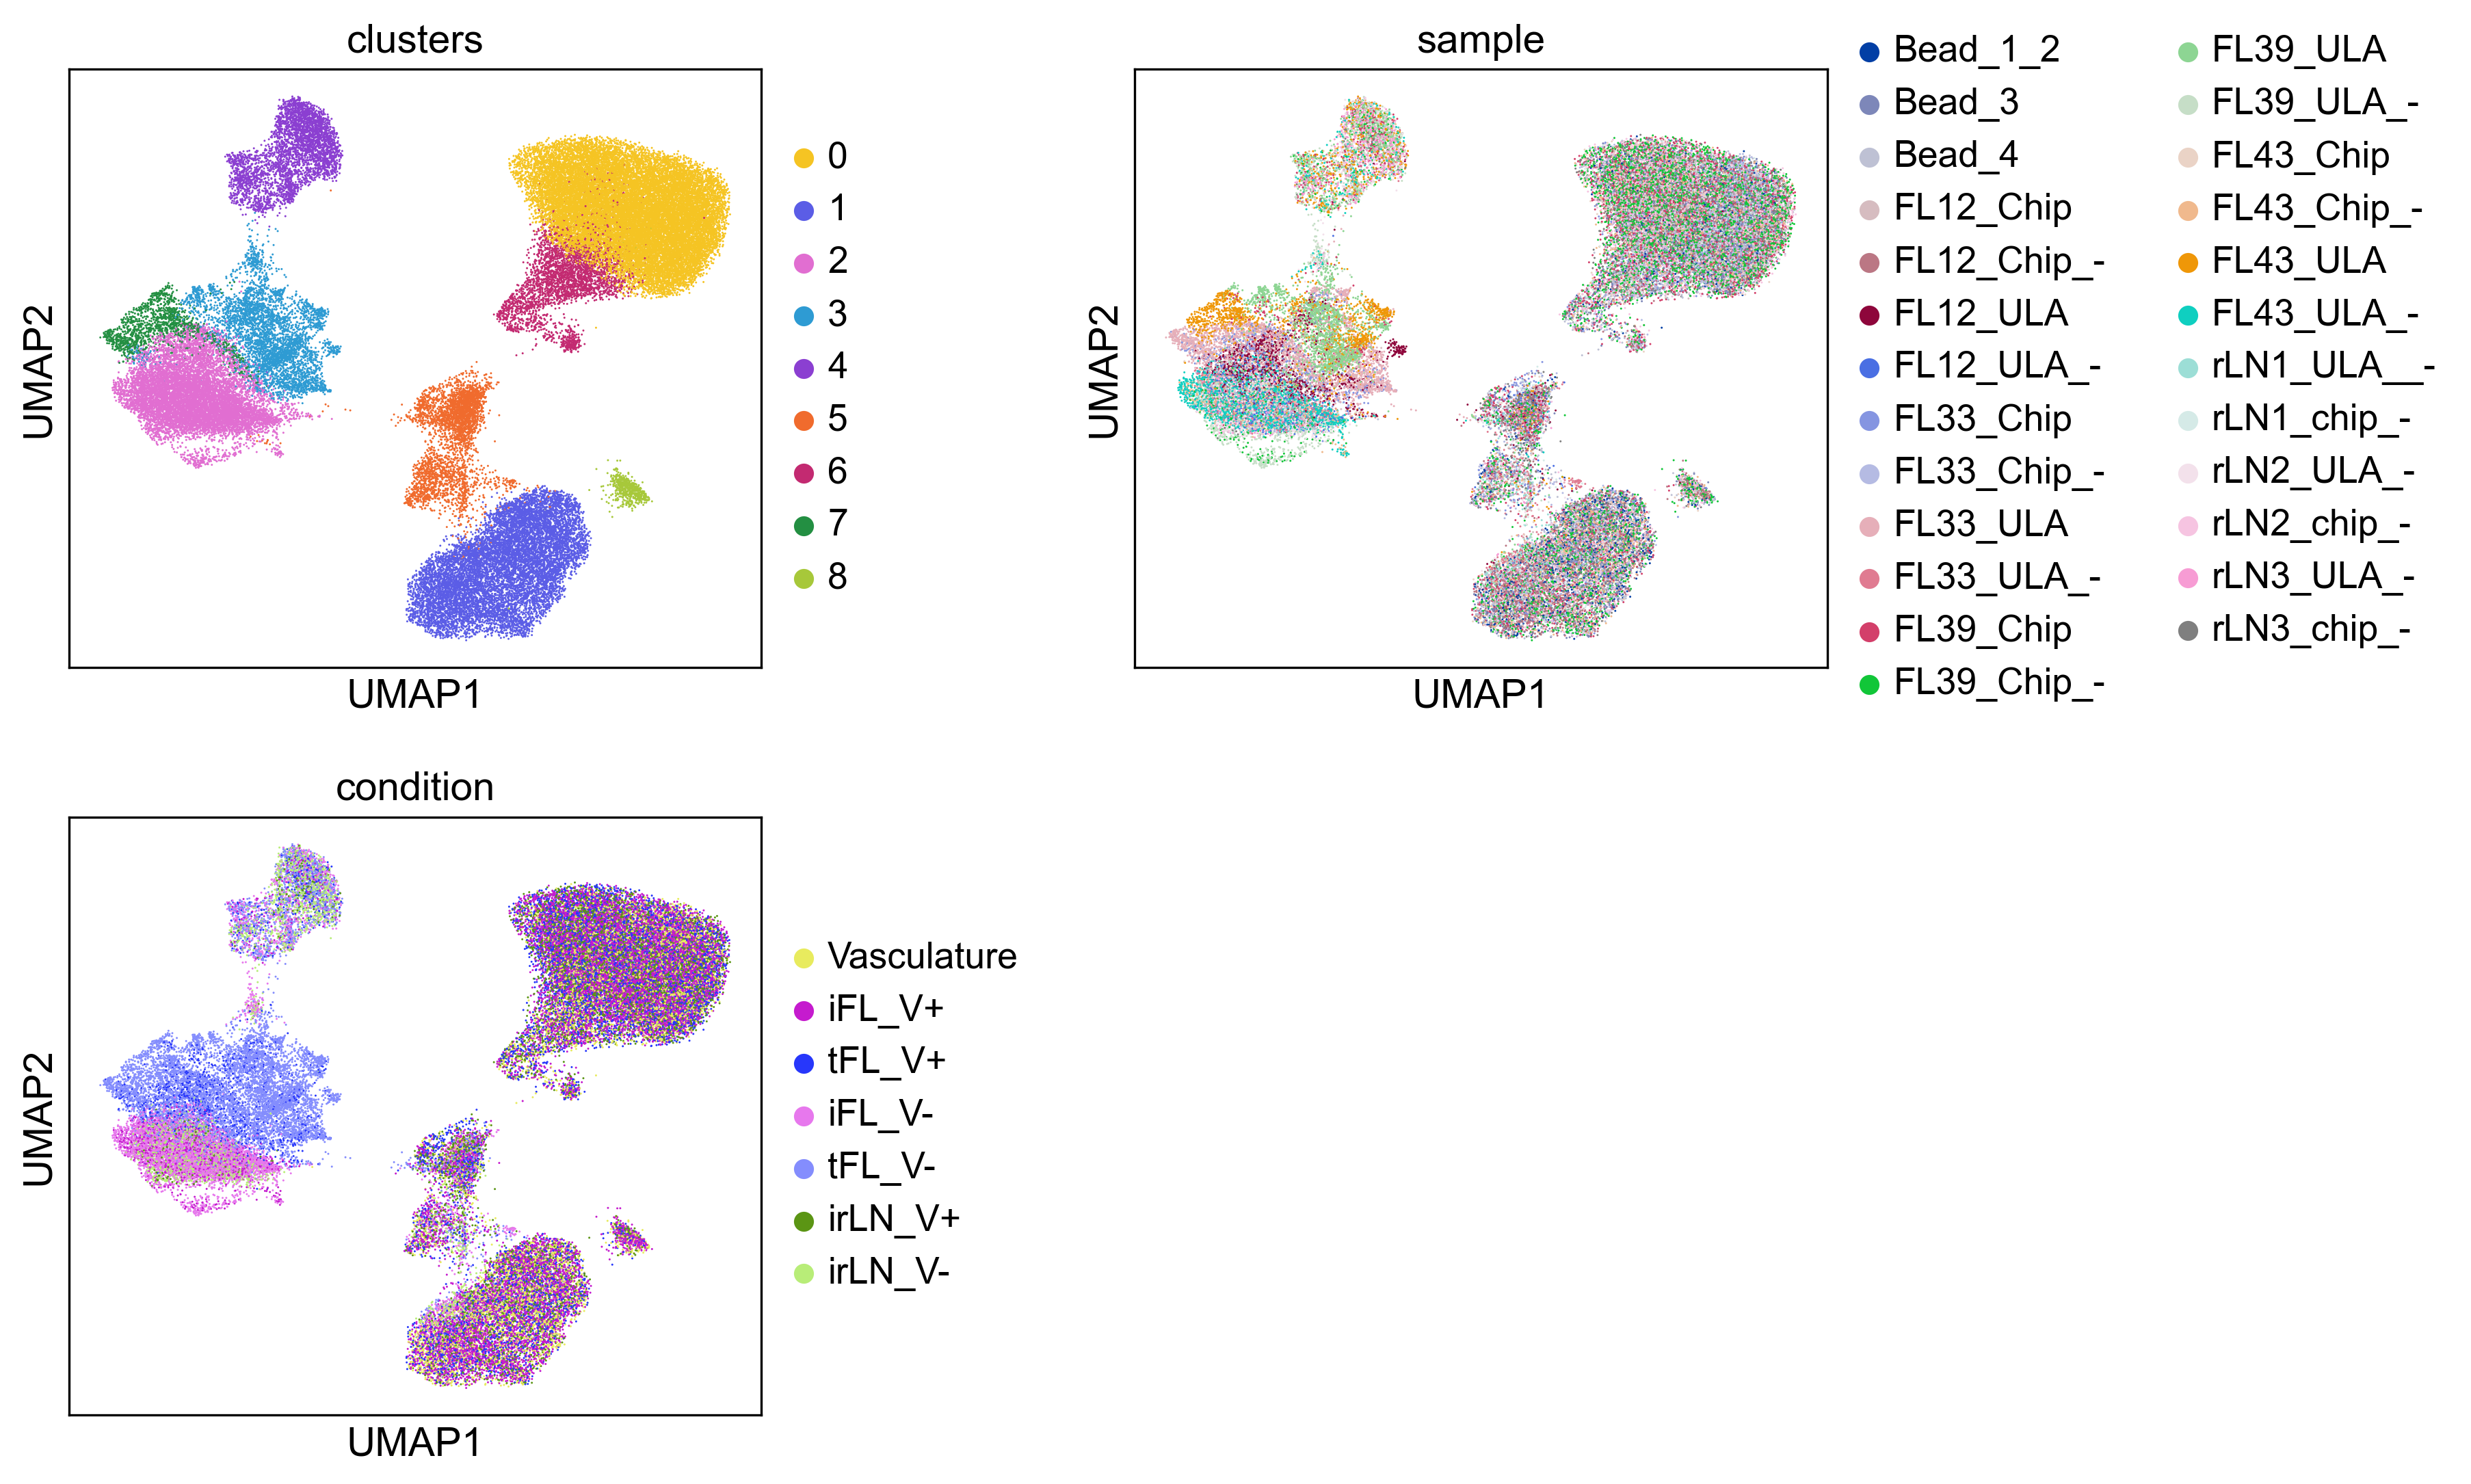

In [35]:
figdir = r"C:\Users\taylorhearn\Desktop\scRNA\in_depth"
os.makedirs(figdir, exist_ok=True)
sc.settings.figdir = figdir

leiden_resolution = 0.6
clean_matrix = r"C:\Users\taylorhearn\Desktop\scRNA\adata_clustered_res_0_6.h5ad"

# --- Colour maps ---
cluster_colourmap = {
    "0": "#F5C423",  # amber
    "1": "#5B5DE6",  # indigo
    "2": "#E16ED1",  # magenta
    "3": "#2E9BD3",  # azure
    "4": "#8B3FD1",  # violet
    "5": "#F06B2D",  # orange (instead of red)
    "6": "#C32A71",  # raspberry
    "7": "#238F42",  # green
    "8": "#A7C83A",  # lime
}
condition_mapping = {
    "Bead": "Vasculature",
    "FL_Chip_minus": "iFL_V+",
    "FL_Chip_plus": "tFL_V+",
    "FL_ULA_minus": "iFL_V-",
    "FL_ULA_plus": "tFL_V-",
    "rLN_Chip_minus": "irLN_V+",
    "rLN_ULA_minus": "irLN_V-",
}
condition_colormap = {
    "Vasculature": "#E8EB5E",
    "iFL_V+": "#C51BCE",
    "tFL_V+": "#2737FB",
    "iFL_V-": "#E778ED",
    "tFL_V-": "#848DFD",
    "irLN_V+": "#5B9514",
    "irLN_V-": "#B8ED78",
}

# Order used for composition bar charts.
condition_order = ["Vasculature", "irLN_V-", "irLN_V+", "iFL_V-", "iFL_V+", "tFL_V-", "tFL_V+"]

# Conditions that carry a vasculature (V+) or bead control, used for signature/ternary views.
vascularised_conditions = ["Vasculature", "iFL_V+", "tFL_V+", "irLN_V+"]


res_0_6 = sc.read_h5ad(clean_matrix)
res_0_6.obs["condition"] = res_0_6.obs["condition"].replace(condition_mapping, inplace=False)
ensure_obs_categories_and_palettes(res_0_6, cluster_colourmap, condition_colormap)

sc.pl.umap(res_0_6, color=["clusters", "sample", "condition"], wspace=0.4, ncols=2,
    save="_overview.png", show=True)


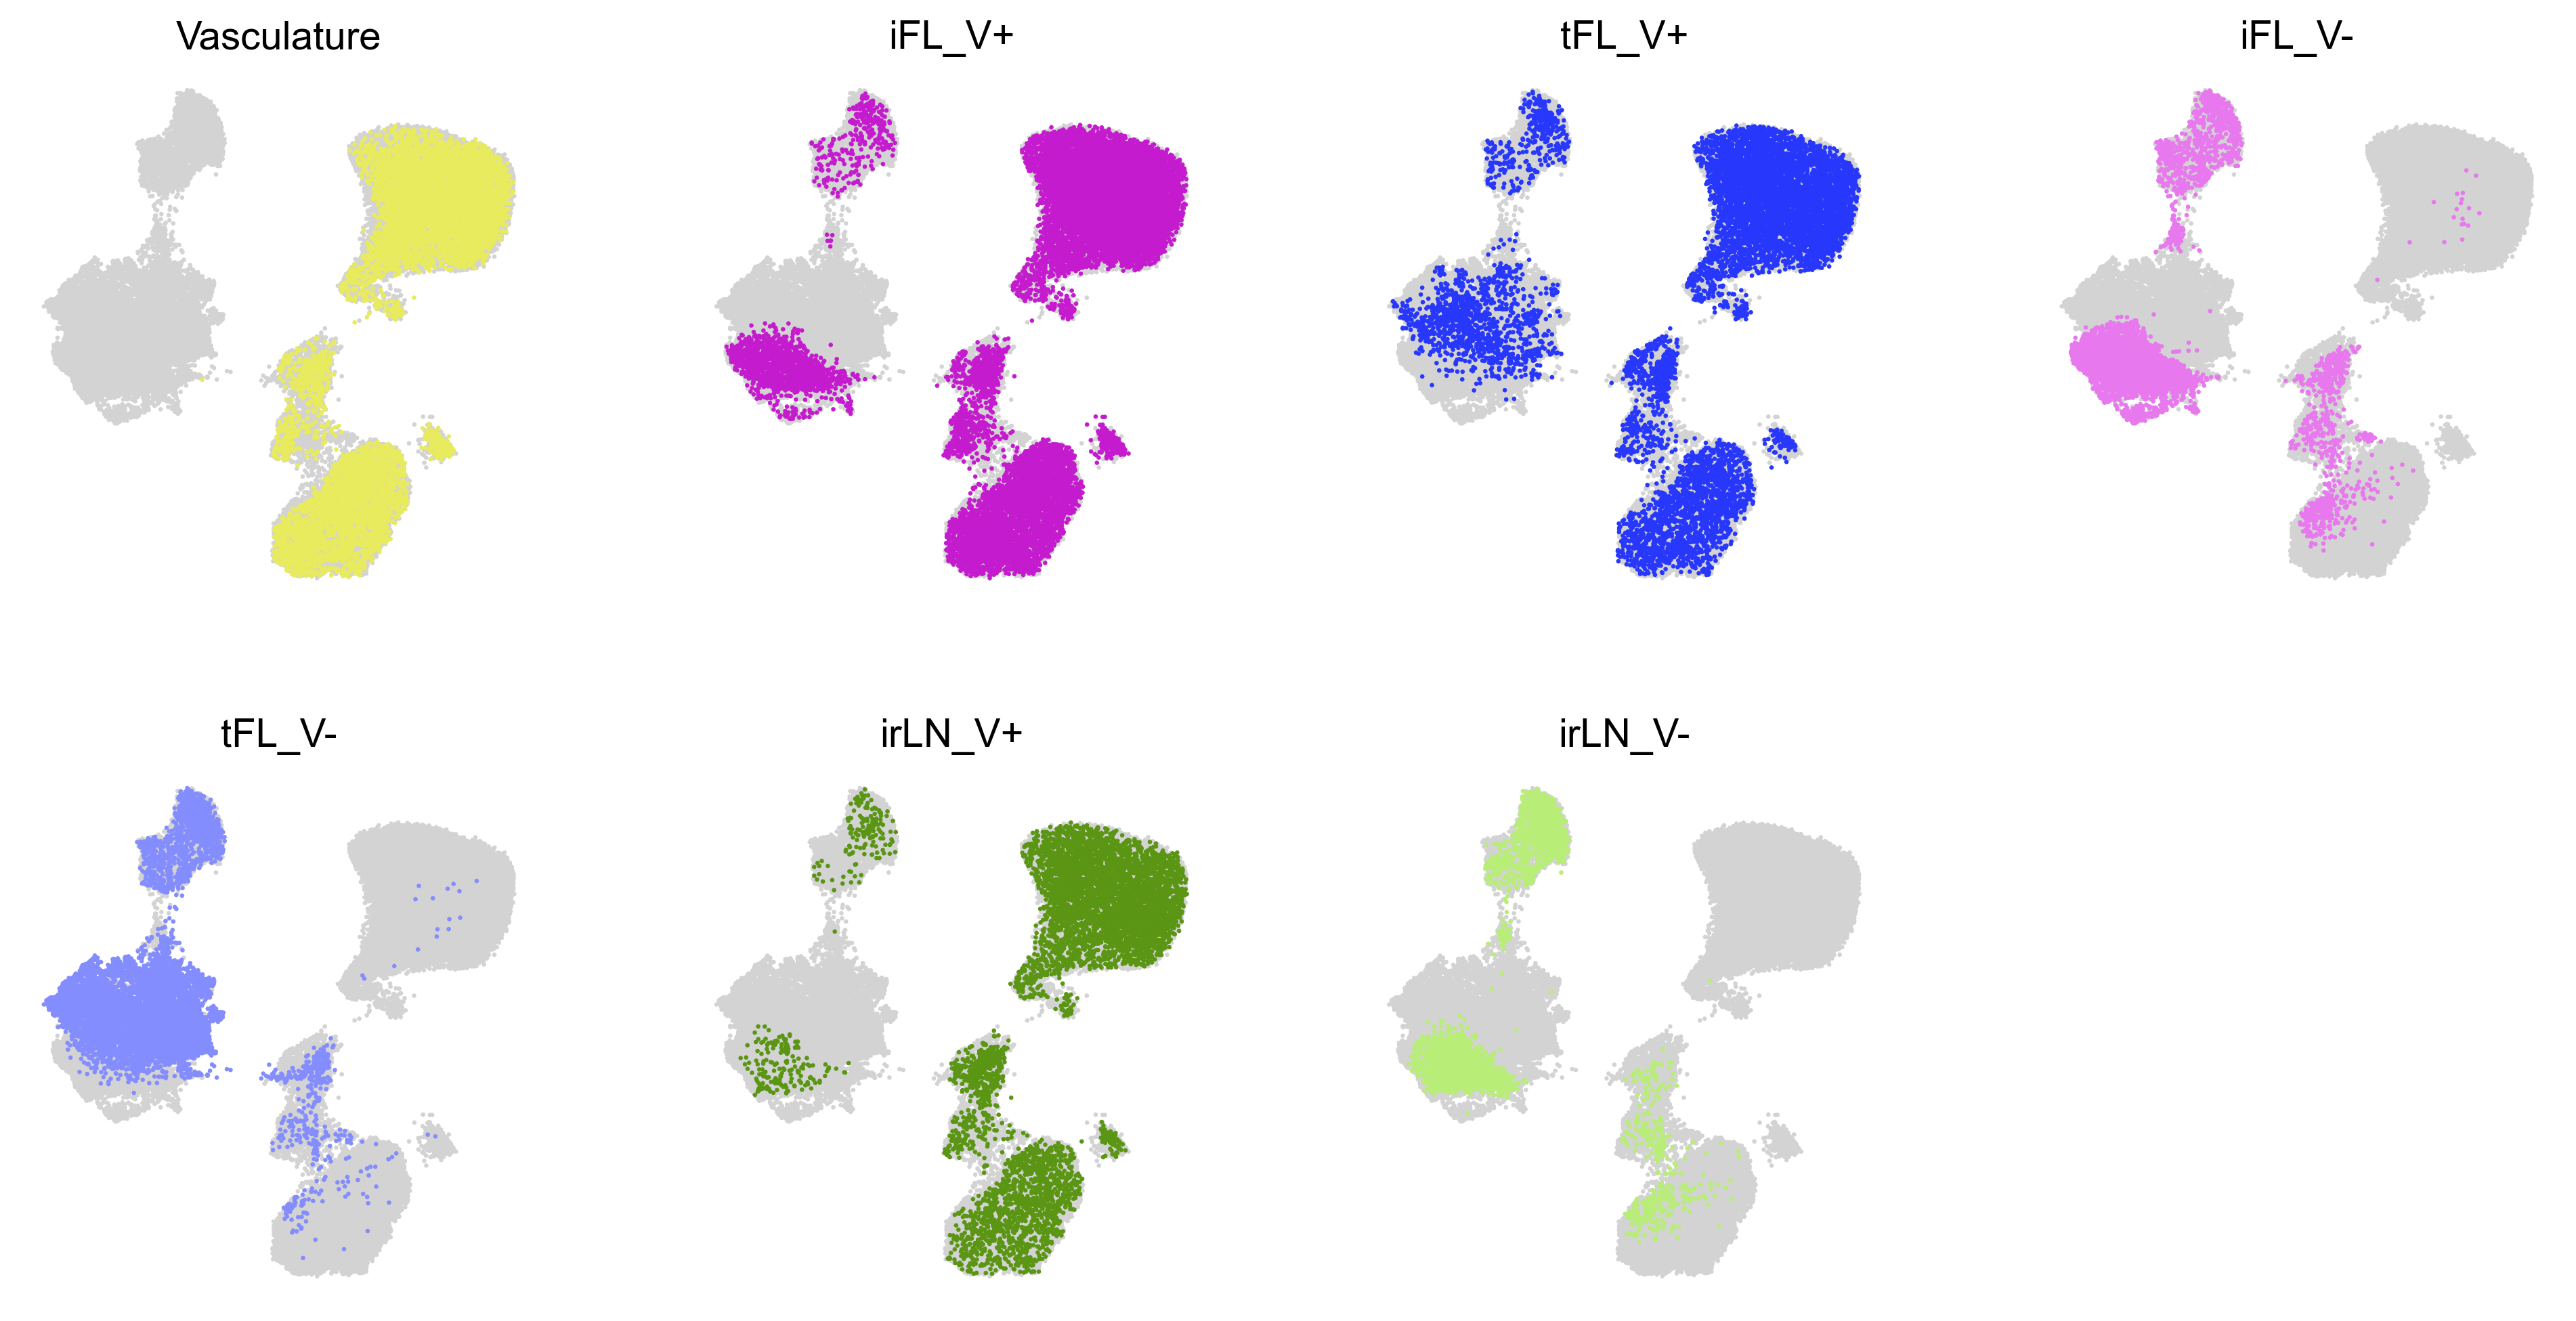

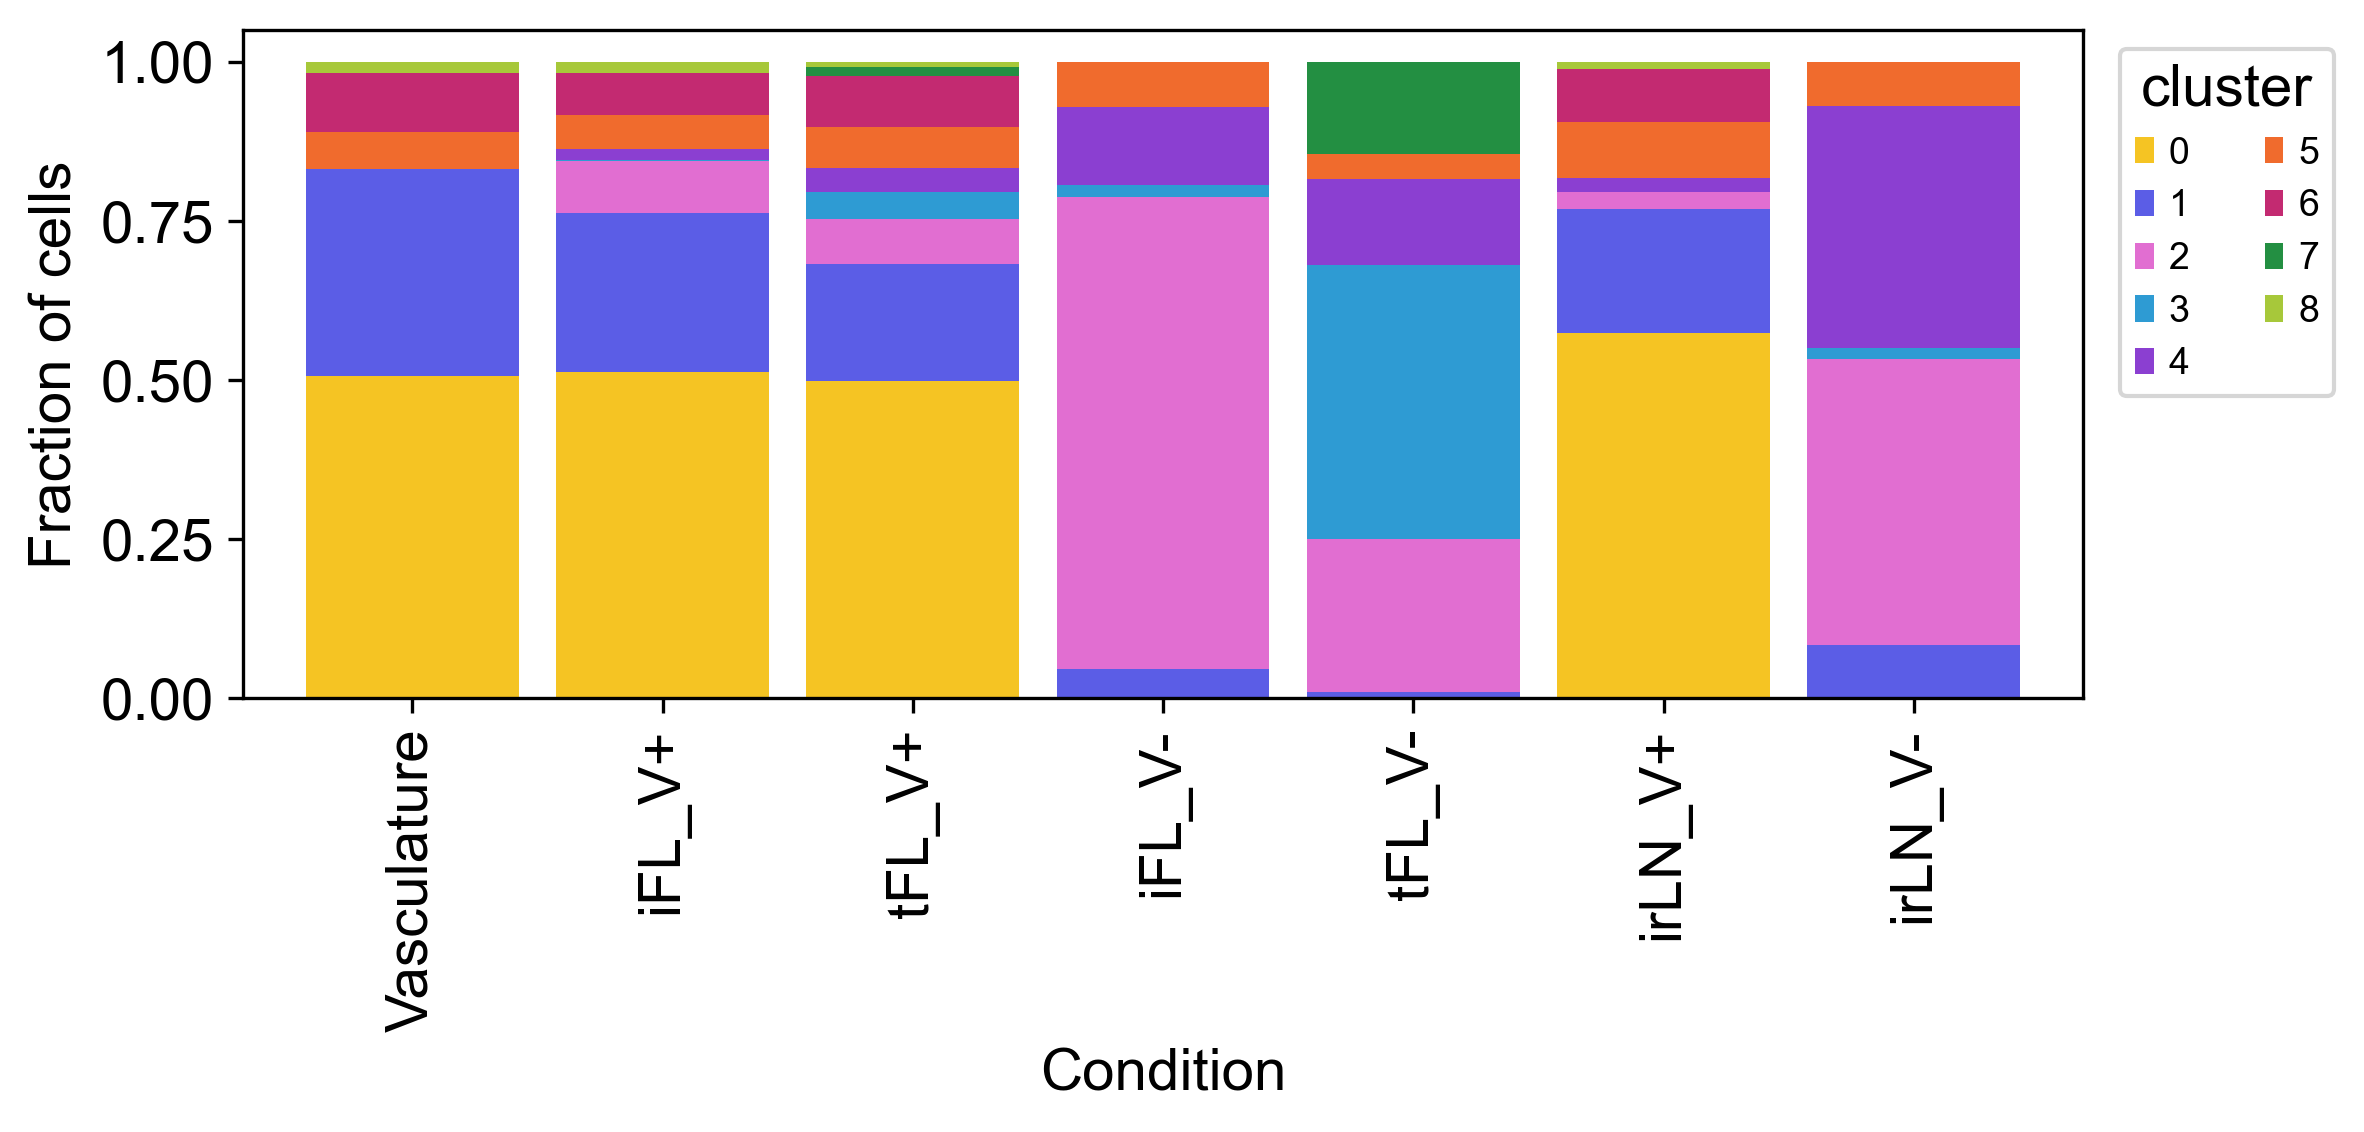

In [36]:
# --- Cluster composition ---
highlight_umap(res_0_6, "condition", size=10, ncols=4,
    output_path=os.path.join(figdir, "umap_condition_highlight.png"), palette=condition_colormap)

plot_cluster_composition(res_0_6, cluster_colormap=cluster_colourmap, output_dir=figdir)

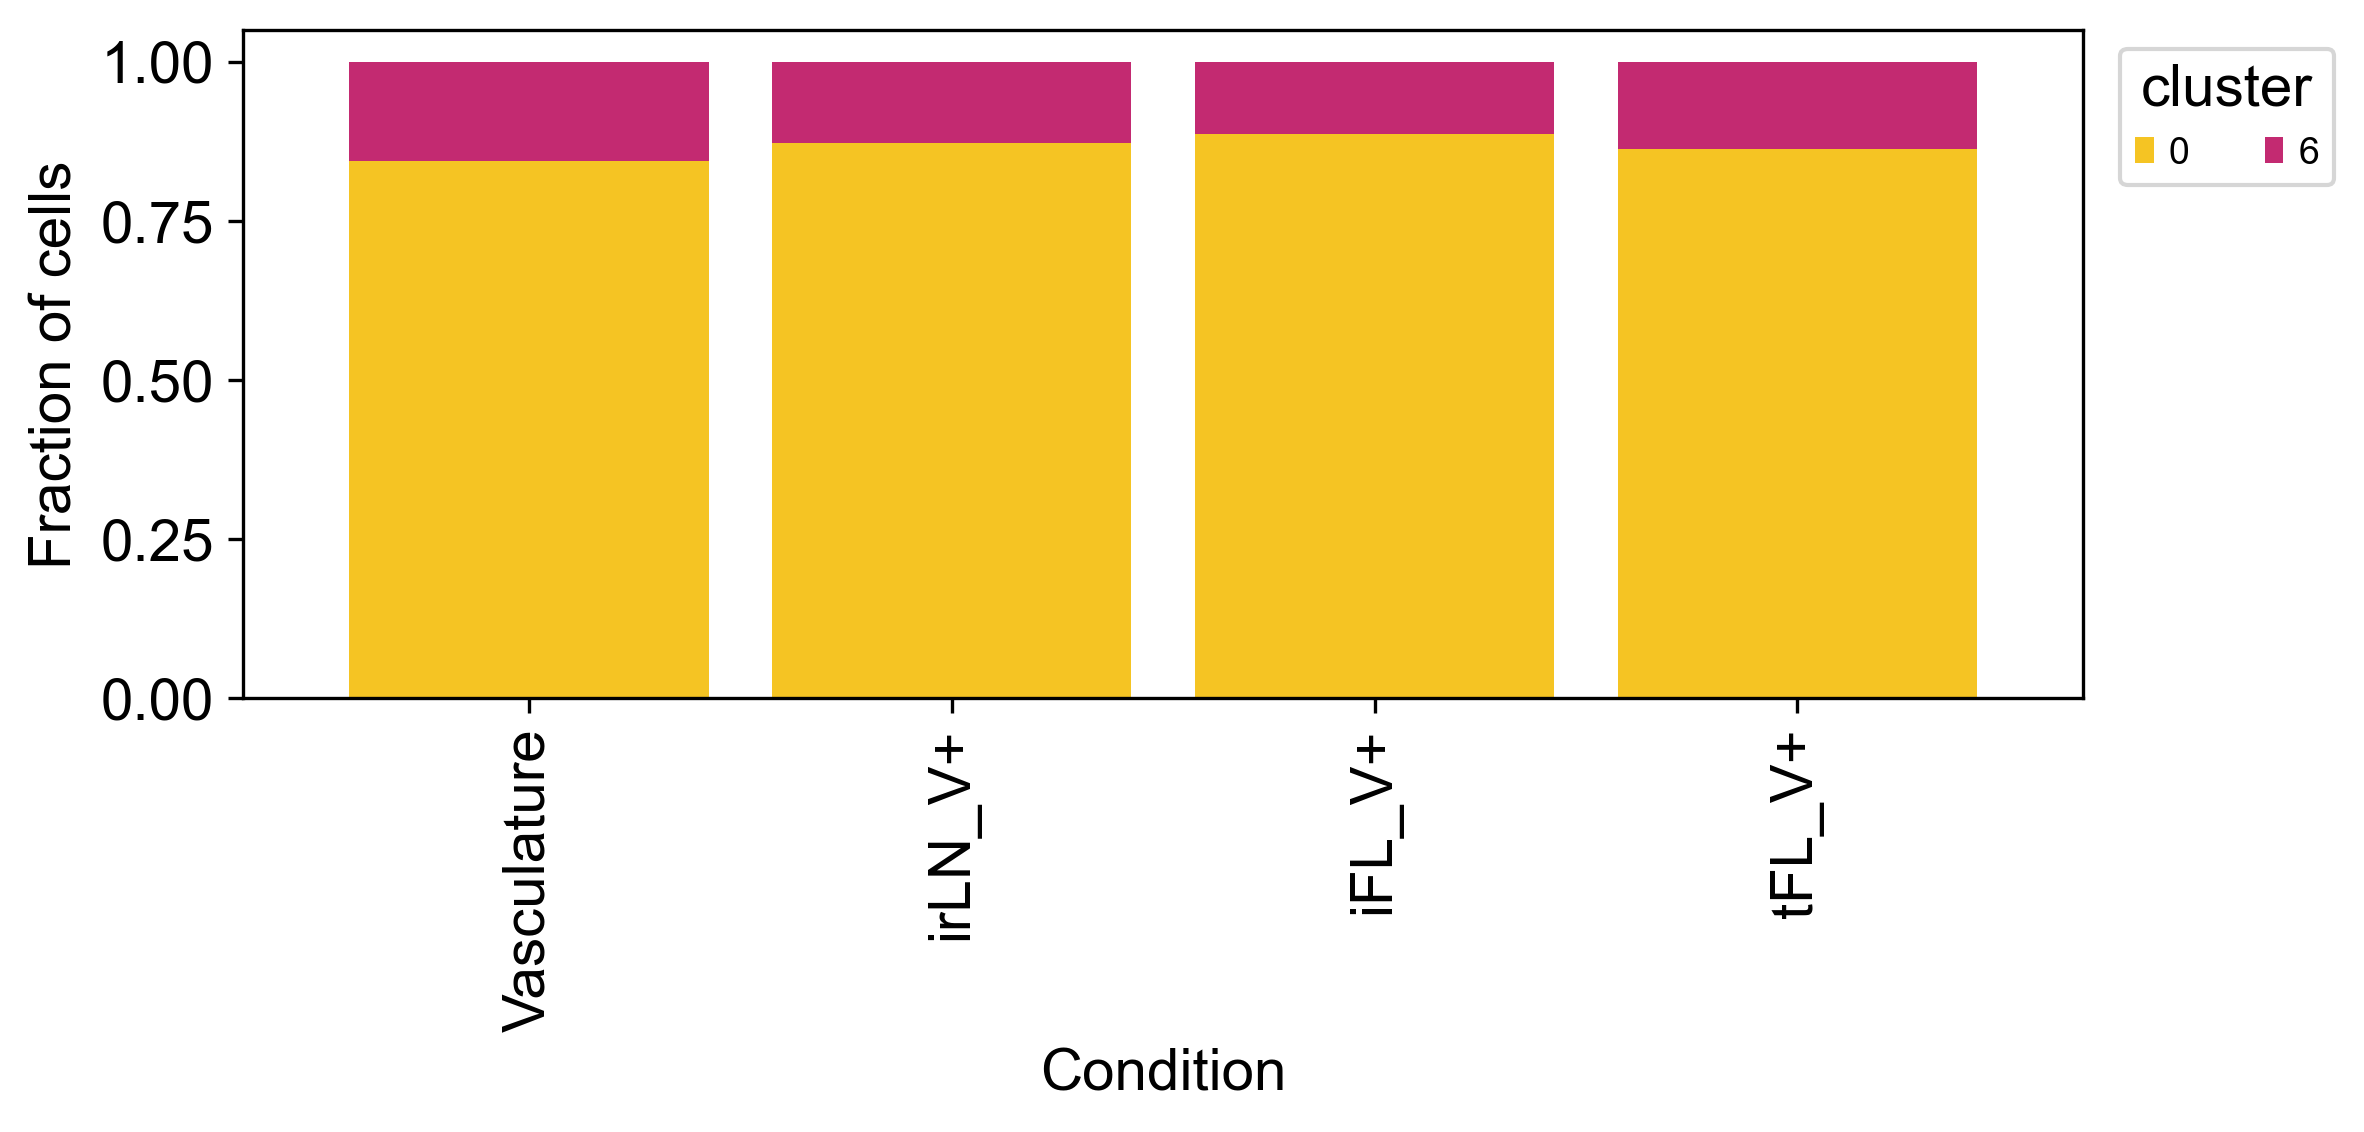

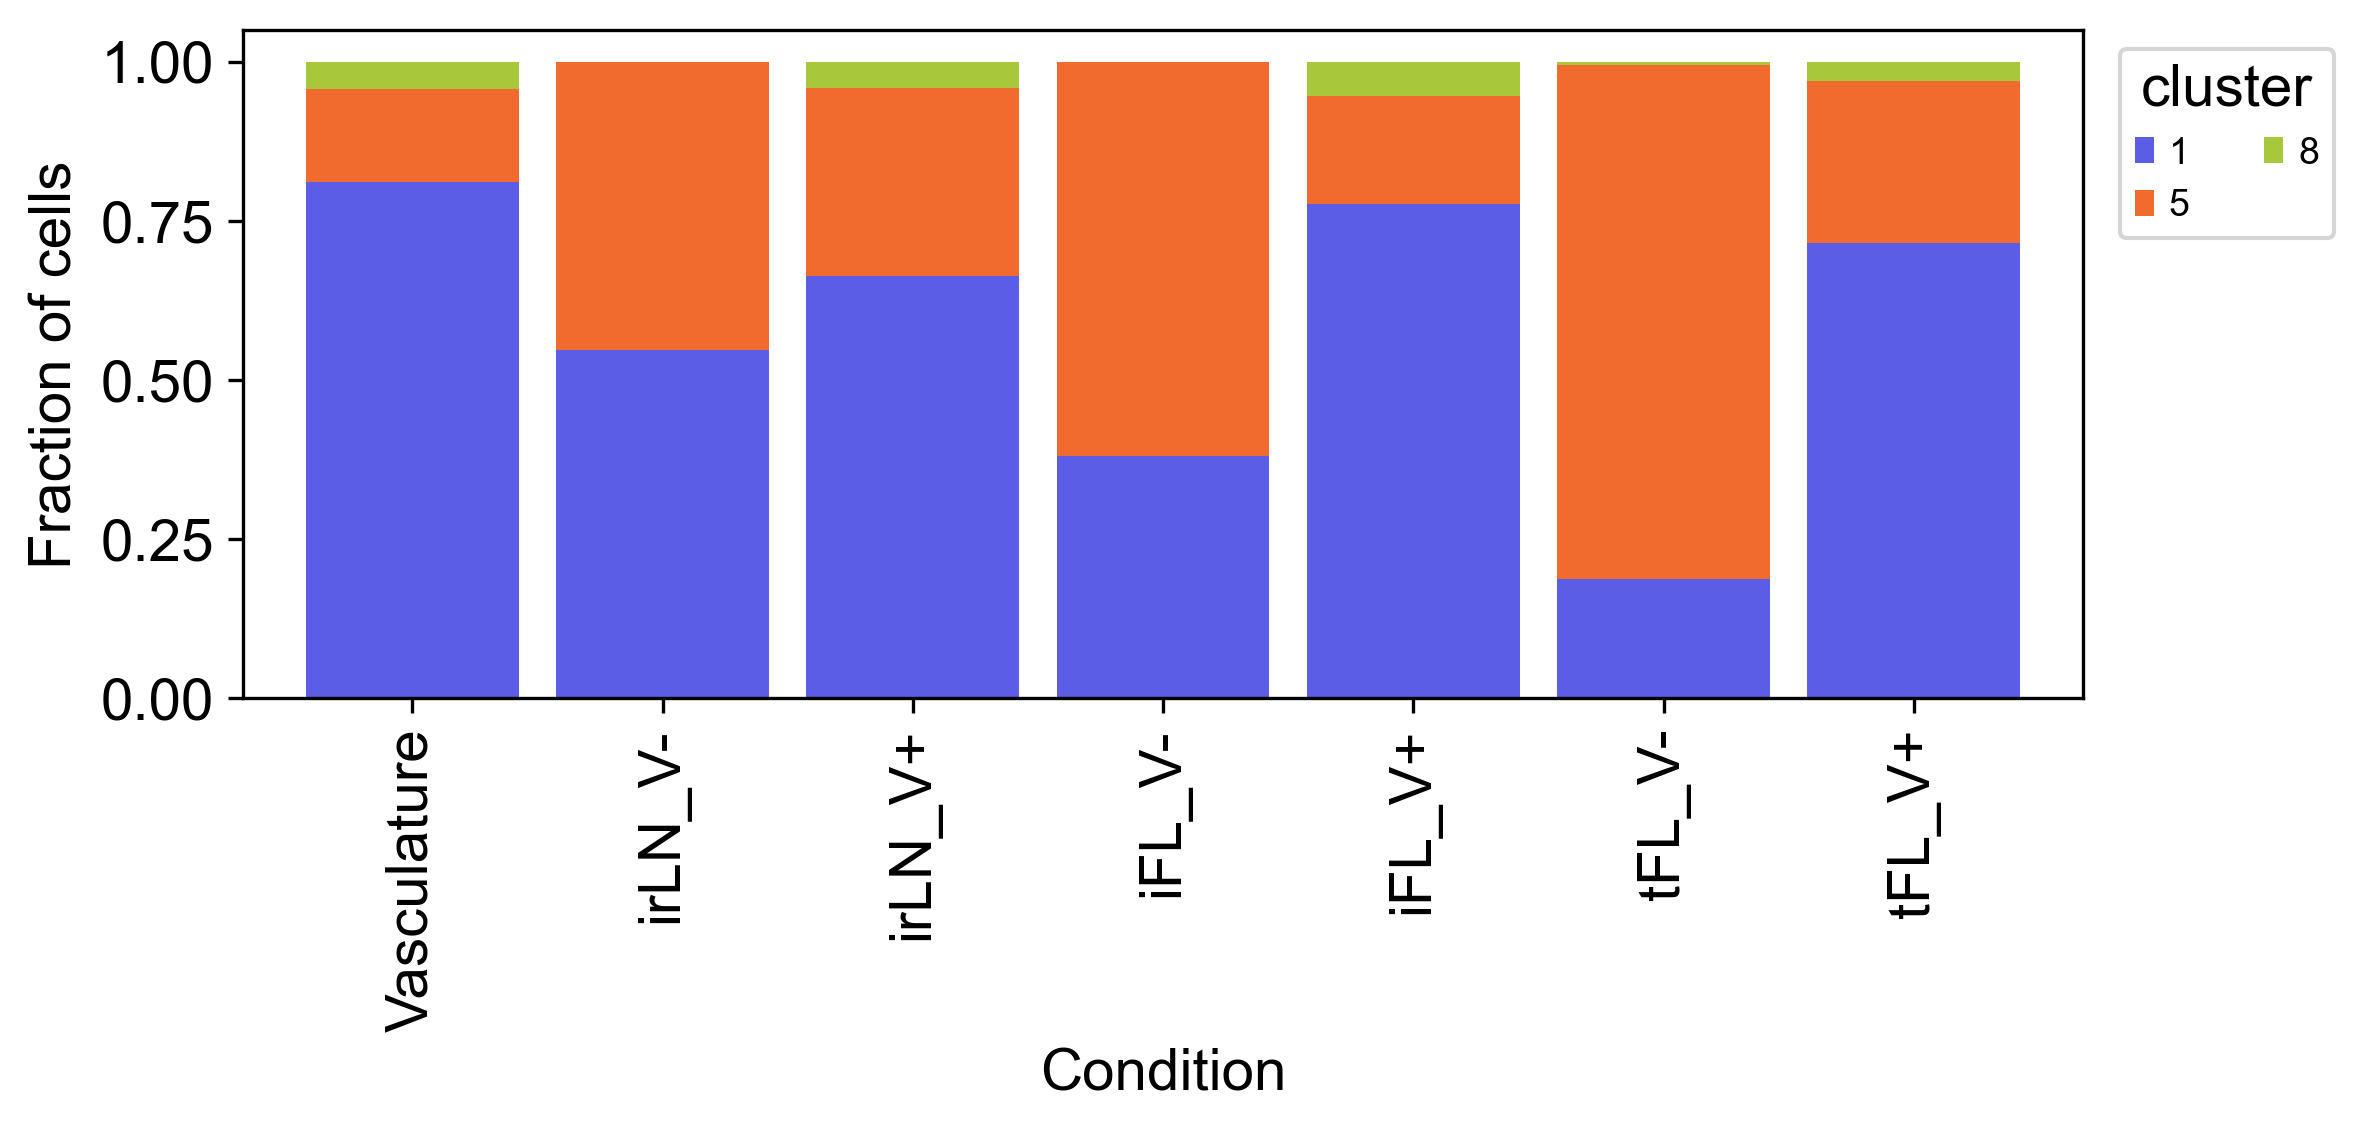

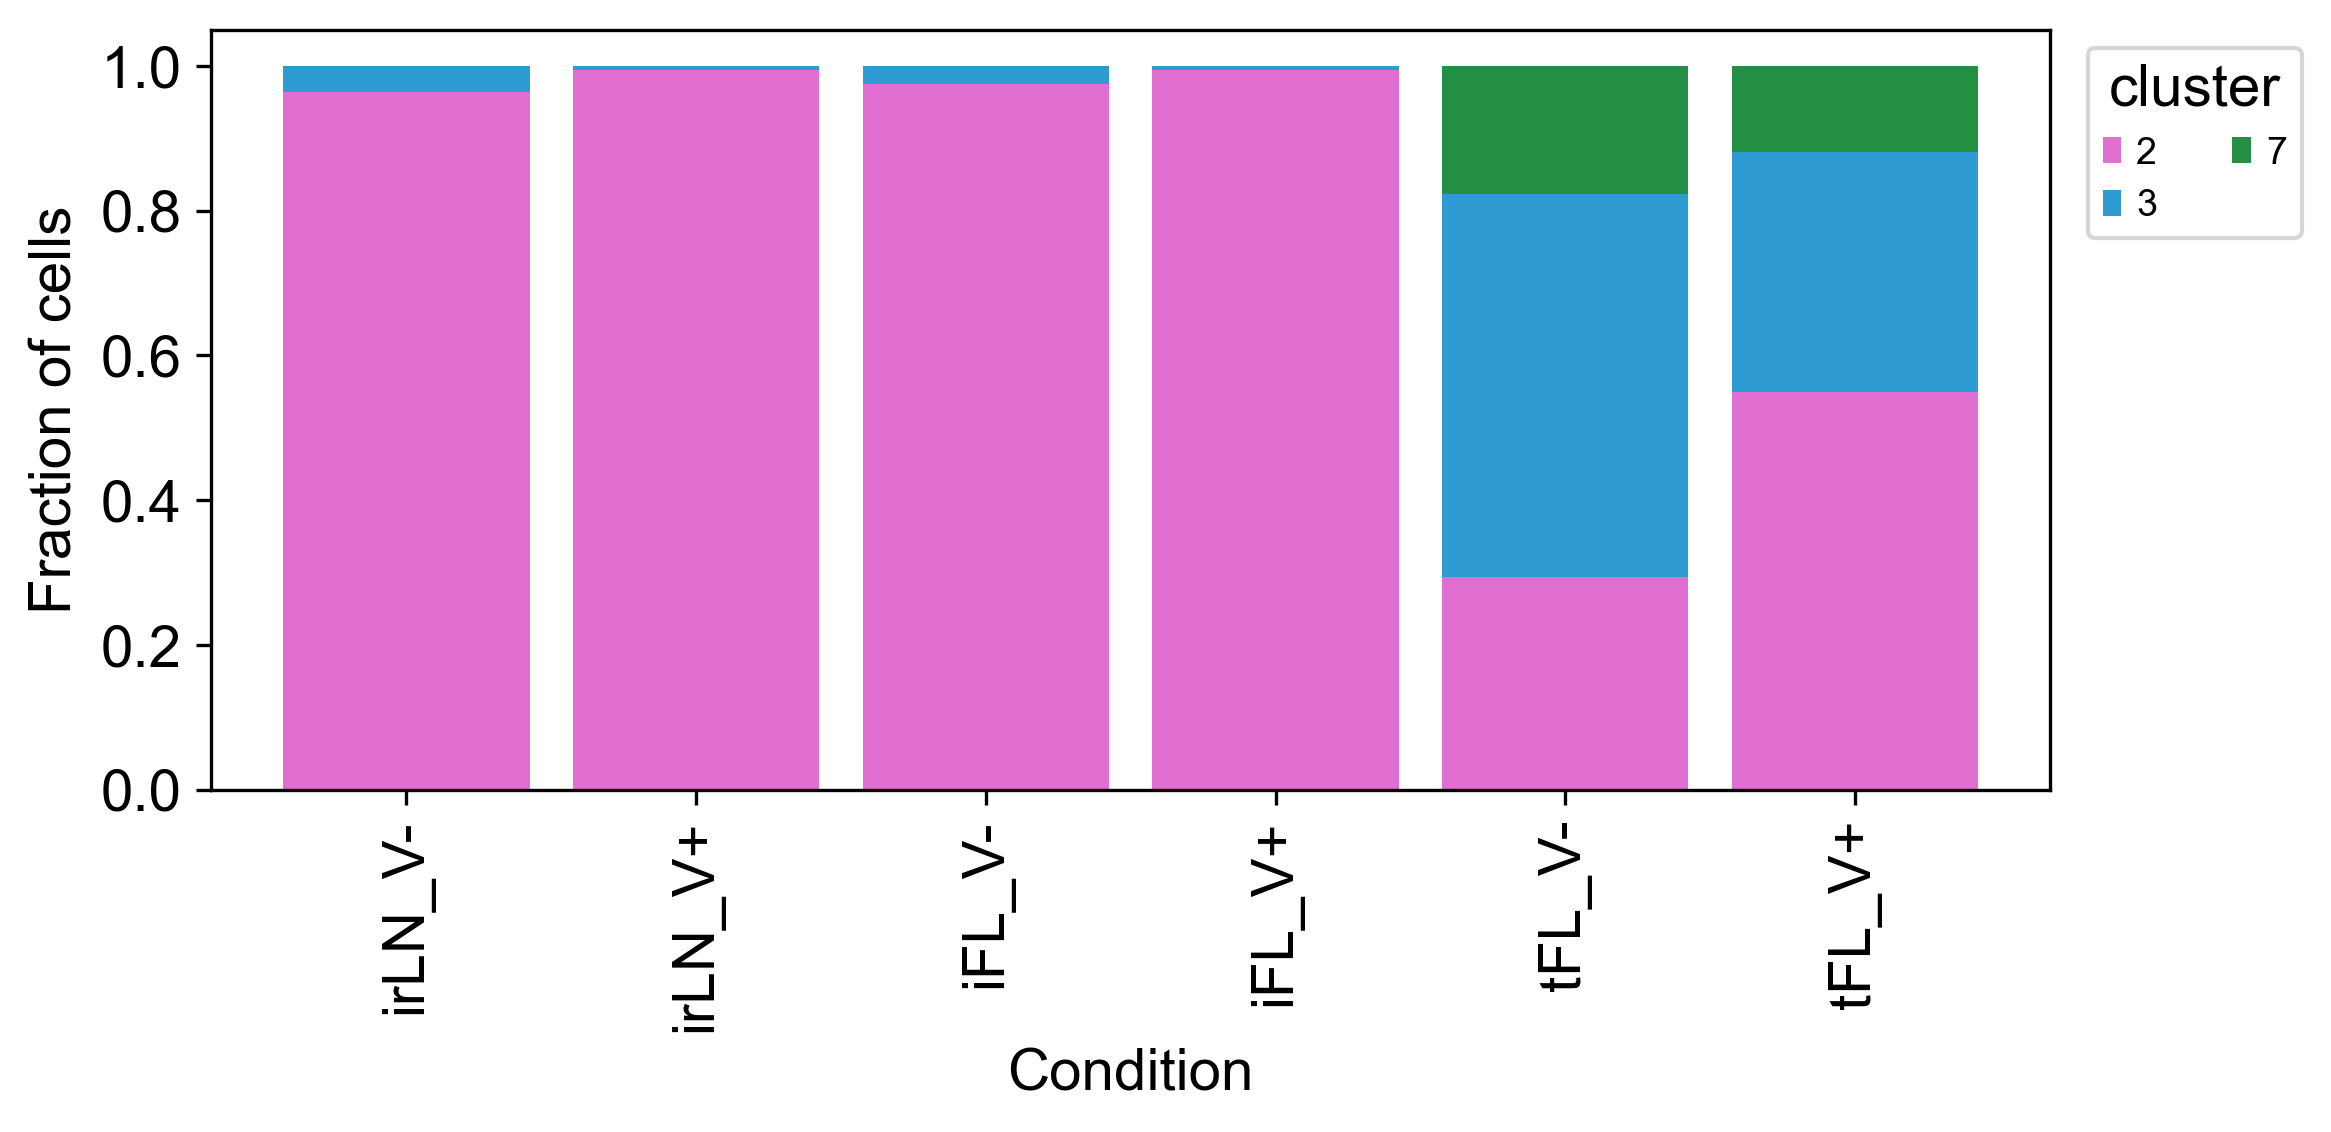

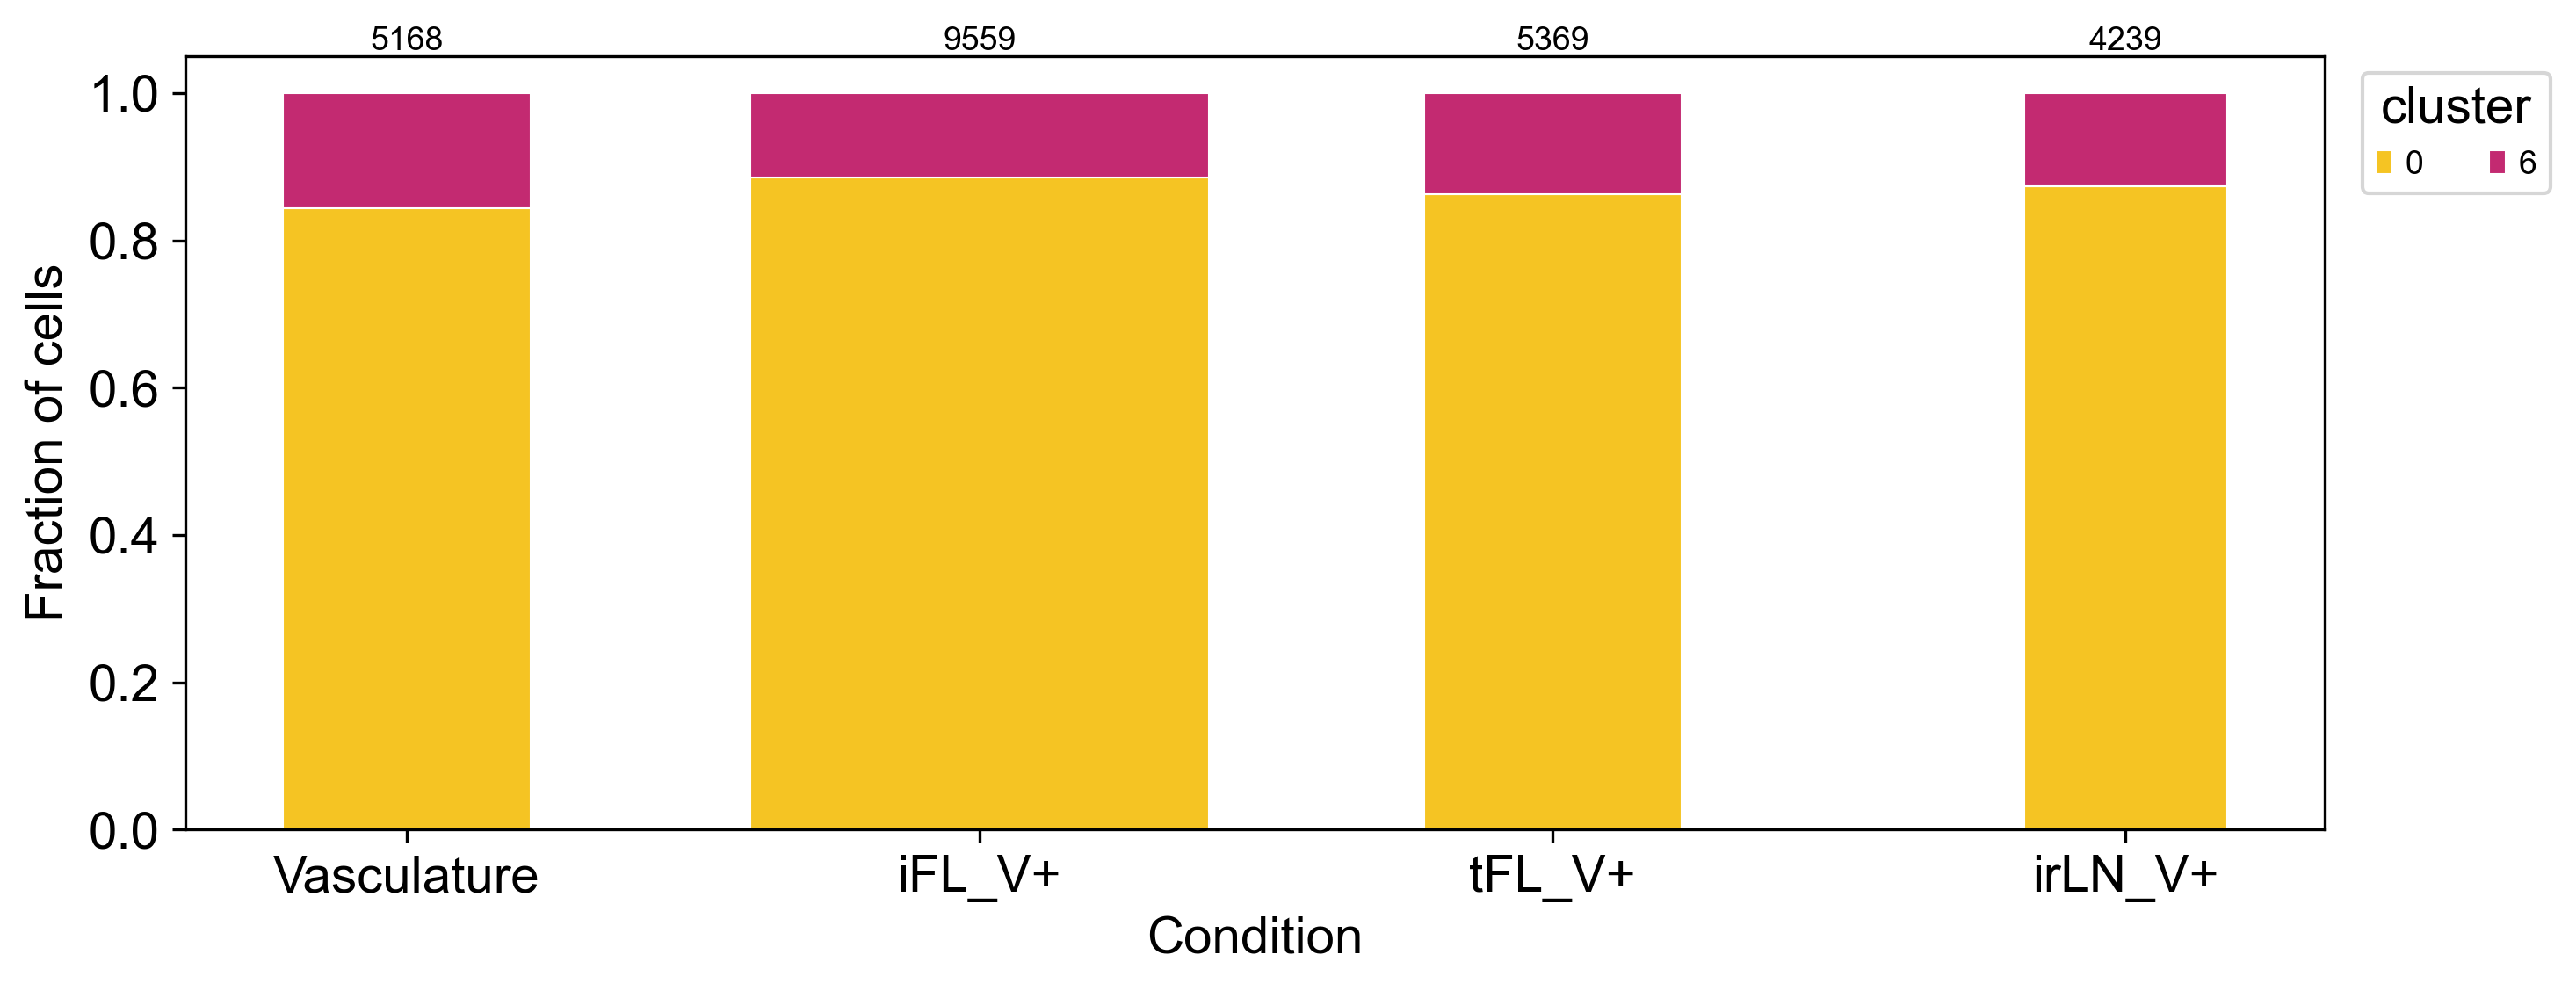

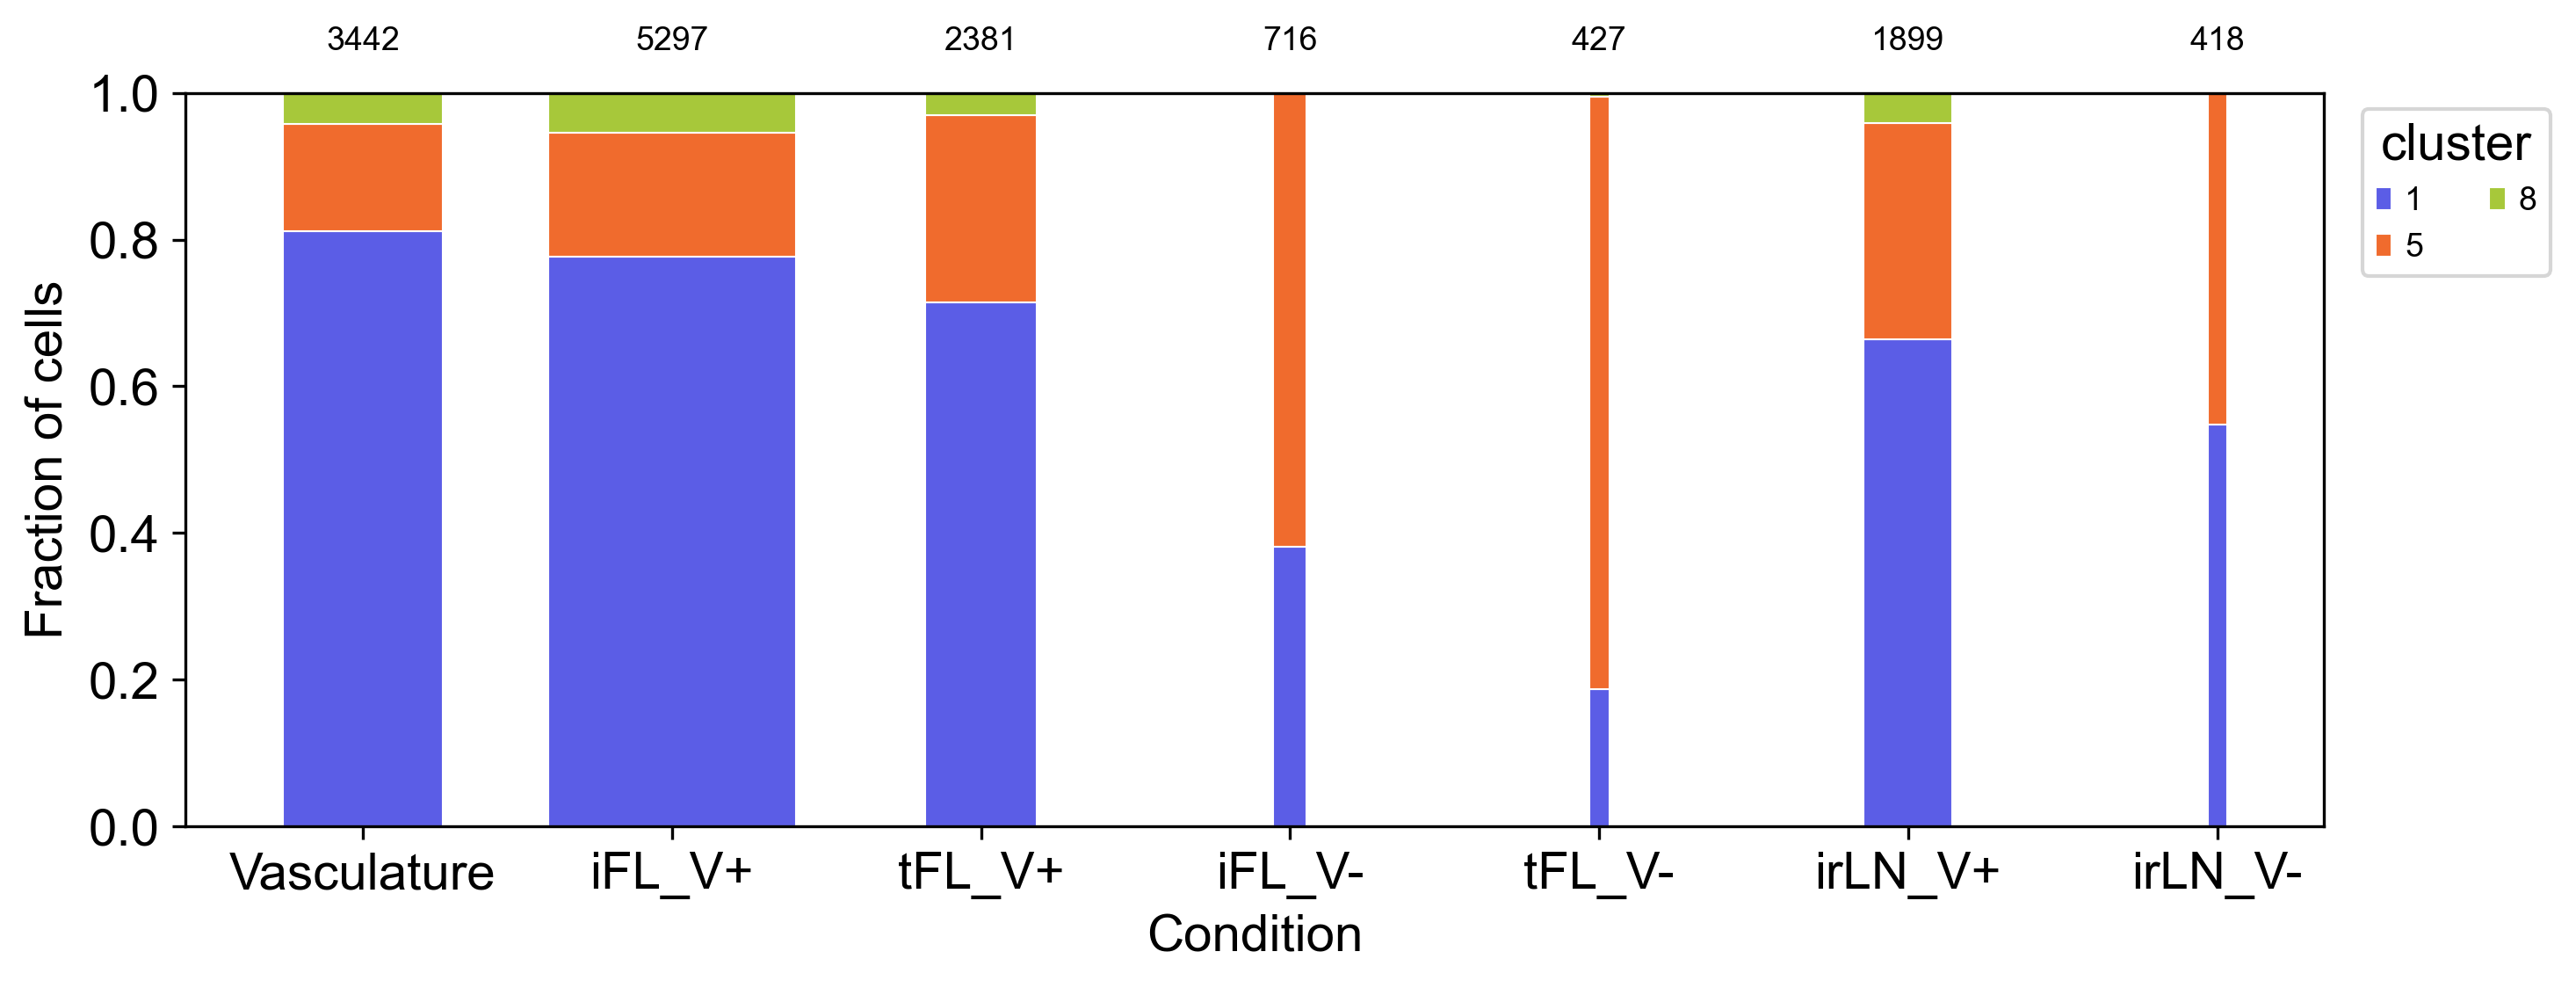

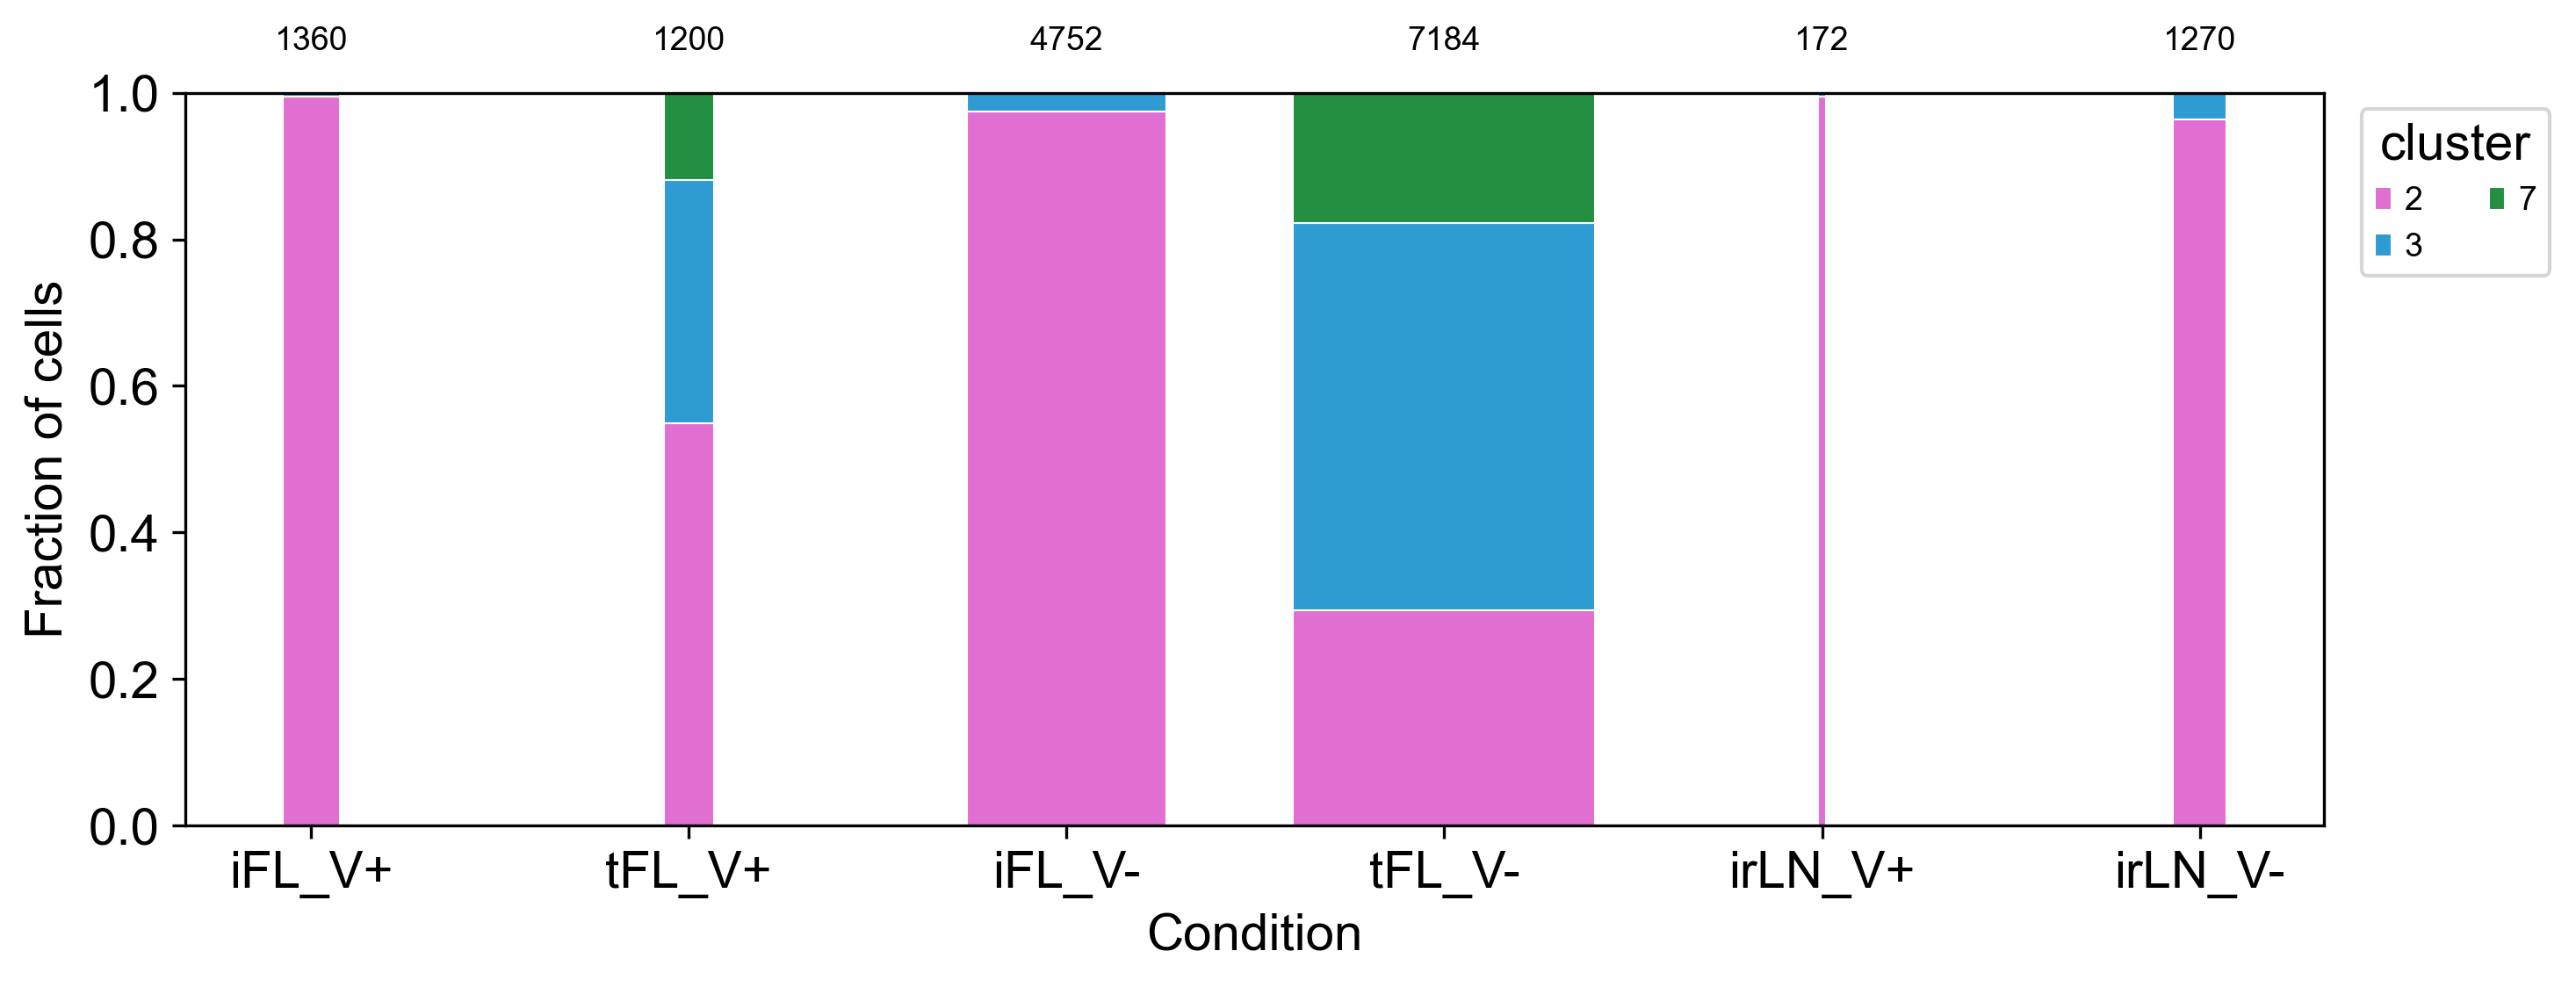

In [37]:
# Split the data into the major lineages for finer composition views.
endothelial_cells = res_0_6[res_0_6.obs["clusters"].isin(["0", "6"])].copy()
fibroblast_cells = res_0_6[res_0_6.obs["clusters"].isin(["1", "5", "8"])].copy()
b_cells = res_0_6[res_0_6.obs["clusters"].isin(["2", "3", "7"])].copy()
cell_types = [endothelial_cells, fibroblast_cells, b_cells]
cell_type_names = ["endothelial_cells", "fibroblast_cells", "b_cells"]

plot_composition_by_celltype(cell_types, cell_type_names, cluster_colourmap, condition_order, figdir)
plot_composition_width_adjusted(cell_types, cell_type_names, cluster_colourmap, figdir)


In [ ]:
# --- Marker genes ---
# Rank marker genes per cluster and show the top 5 (by p-value), coloured by log fold change.
sc.tl.rank_genes_groups(res_0_6, groupby="clusters", method="wilcoxon", use_raw=True, rankby_abs=True)
sc.pl.rank_genes_groups_dotplot(res_0_6, n_genes=5, values_to_plot="logfoldchanges", cmap="bwr",
    vmin=-4, vmax=4, colorbar_title="log fold change", save="_markers.png", show=True)

# Canonical human immune markers grouped by lineage (lymph node / lymphoma context).
immune_markers = {
    "B cell": ["CD19", "MS4A1", "CD79A", "CD79B"],
    "Germinal center B": ["BCL6", "AICDA", "RGS13", "LMO2"],
    "FL B cell": ["BCL2", "MME"],
    "Plasma": ["MZB1", "XBP1", "PRDM1", "SDC1"],
    "T cell": ["CD3D", "CD3E", "CD2"],
    "CD4 T": ["CD4", "IL7R"],
    "CD8 T": ["CD8A", "CD8B", "GZMK"],
    "Tfh": ["CXCL13", "PDCD1", "ICOS"],
    "NK": ["NKG7", "GNLY", "KLRD1"],
    "Myeloid/DC": ["LYZ", "CD68", "ITGAX"],
    "Endothelial": ["PECAM1", "VWF", "CDH5", "CLDN5"],          # blood vessels
    "Lymphatic endothelial": ["PROX1", "LYVE1", "PDPN"],       # lymphatic sinuses
    "Fibroblast/stromal": ["PDGFRA", "PDGFRB", "COL1A1", "COL3A1", "DCN", "LUM"],
    "FRC": ["ACTA2", "PDPN", "CCL19", "CCL21"],                 # fibroblastic reticular cells
    "FDC": ["CR2", "CR1", "FDCSP", "CLU"],                      # follicular dendritic cells
    "Proliferating": ["MKI67", "TOP2A"],
}
plot_canonical_markers(res_0_6, immune_markers, groupby="clusters")


# --- Individual gene -> cluster annotation ---
individual_genes = pd.read_excel(r"z:\Bel\Marina_Side_Projects\scRNA\SIGNATURE PDLT.xlsx")
individual_genes = annotate_individual_genes(
    res_0_6, individual_genes, output_csv=r"individual_gene_clusters_annotated.csv")
print(individual_genes)


# --- Key gene expression ---
# key_genes = [g for g in individual_genes.Gene if g in res_0_6.var_names]
key_genes = ["CD83", "CD40", "SELE"]

sc.pl.umap(res_0_6, color=key_genes, ncols=4, cmap="Reds", use_raw=True, save="_key_genes.png", show=True)

for gene in key_genes:
    violinplot_gene(res_0_6, gene, groupby="clusters", output_dir=figdir,
        filename=f"{gene}_violin.png", palette=cluster_colourmap)

# Split each key gene across conditions and across samples.
plot_genes_by_group(res_0_6, key_genes, groupby="condition", output_dir=figdir, save_name="key_genes.png")
plot_genes_by_group(res_0_6, key_genes, groupby="sample", output_dir=figdir, save_name="key_genes.png")



In [ ]:
# --- Gene signatures ---
# When use_raw=True, scoring happens against res_0_6.raw — filter genes against that.
gene_universe = res_0_6.raw.var_names if res_0_6.raw is not None else res_0_6.var_names

# Newer signatures: score only the vascularised conditions.
signature_df_new = pd.read_csv("marina_gene_signatures_new.csv")
vascularised_res_0_6 = res_0_6[res_0_6.obs["condition"].isin(vascularised_conditions)].copy()
plot_signature_umap(vascularised_res_0_6, signature_df_new, gene_universe, figdir)

# Original signatures: score the full dataset.
signature_df = pd.read_csv("marina_gene_signatures.csv")
plot_signature_umap(res_0_6, signature_df, gene_universe, figdir)

In [ ]:
### TRIANGLE PLOTS
ternary_signatures = pd.read_excel("marina_sequencing_ternary.xlsx")
signatures = {
    sig: grp["Gene name"].dropna().astype(str).tolist()
    for sig, grp in ternary_signatures.groupby("Signature")
}
print("Signatures found:", list(signatures))   # sanity-check the names

score_ternary_proportions(res_0_6, signatures)
plot_ternary_per_condition(res_0_6, vascularised_conditions, condition_colormap, figdir)


In [ ]:
### PSEUDOBULK ANALYSIS/VOLCANOES
# # Restrict to clusters 5-8 (as in the original analysis); pass clusters=None for all clusters.
de_clusters = res_0_6.obs["clusters"].cat.categories[5:]
pseudobulk_results = run_pseudobulk_de_all_pairs(res_0_6, figdir, clusters=de_clusters)


# --- Top DE genes per cluster, split by sample ---
plot_top_degs_by_sample(res_0_6, figdir, n_clusters=9)

# --- Per-lineage marker heatmaps / dotplots / matrixplots ---
plot_celltype_marker_heatmaps(cell_types, cell_type_names, n_genes=20)